# CDS4003 – Data Science Final Project
## Notebook 01 – Stages 1 to 3: Business Problem, Data Collection, Data Understanding and Cleaning

**Project:** Used Vehicle Price Prediction and Market Valuation Using Machine Learning
**Dataset:** Craigslist Cars and Trucks Dataset (author: Austin Reese) – <https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data>
**Target variable:** `price` (regression)

---

## 1. Notebook Introduction

The project is split into **four numbered notebooks** that hand their results to each other through one project folder in your **Google Drive** (`Used-Vehicle-Price-Prediction`). This keeps every notebook short and fast, avoids memory problems, and matches the numbered-notebook structure requested for the GitHub repository.

| Notebook | Stages | Main output |
|---|---|---|
| **01 (this one)** | 1 Business problem · 2 Data collection · 3 Data understanding and cleaning | `data/processed/vehicles_cleaned.csv`, quality reports, audit log |
| 02 | 4 Exploratory data analysis and feature engineering | EDA figures, `src/vehicle_features.py` |
| 03 | 5 Model selection · 6 Tuning and evaluation | `models/price_model.joblib`, metrics, error analysis |
| 04 | 7 Deployment (Streamlit app, README, requirements, GitHub) | `app/app.py`, `requirements.txt`, `README.md`, final package |

**Run the notebooks in order (01 → 02 → 03 → 04).**

### What this notebook does
Stage 1 states the business problem. Stage 2 documents and verifies the dataset. Stage 3 inspects the data, measures its quality, cleans it, proves the improvement with before/after numbers, and saves the cleaned dataset for notebook 02. **No machine-learning model is trained here.**

### How to run
1. Put `vehicles.csv` anywhere in your Google Drive (or keep it where it already is).
2. Run the cells from top to bottom. In Section 3 the notebook **finds the file in your Drive automatically** and copies it to Colab's fast local disk. Browser upload is only a fallback.
3. At the end, the cleaned data and reports are saved in `MyDrive/Used-Vehicle-Price-Prediction/`.

### Record-keeping names used in this notebook
| Variable | Meaning |
|---|---|
| `df_raw` | The dataset exactly as loaded. **Never modified.** |
| `df_working` | An untouched copy used for inspection and analysis in Sections 4–12. |
| `df_cleaned` | The dataset produced by the cleaning workflow in Section 13. |

> **Academic honesty:** all numbers are calculated from your data when you run the notebook. List any AI tools you used in your report, and be ready to explain every step orally.

---
# STAGE 1 – Business Problem Formulation

### Business context
Used-vehicle marketplaces (Craigslist, dealer portals, classifieds) contain millions of listings whose asking prices are set by sellers without a common reference. Prices depend on manufacturer, model, age, mileage, condition, fuel, transmission, body type and location.

### Problem statement
*Buyers, sellers and dealerships cannot easily judge whether a used-vehicle asking price is reasonable. Over-pricing delays sales; under-pricing loses money; buyers risk overpaying.*

### Stakeholders and value
| Stakeholder | Value of a price-estimation tool |
|---|---|
| Private sellers | Choose a competitive asking price faster |
| Buyers | Check whether an asking price is fair before negotiating |
| Dealerships / marketplaces | Price inventory consistently, flag listings priced far from the market |

### Objectives (SMART)
1. **Specific:** build a regression model that predicts the asking `price` (US dollars) of a used car or truck from its attributes.
2. **Measurable (initial targets – to be reviewed with the instructor at Milestone 1):**
   - Test-set **R² ≥ 0.75** (dollar scale)
   - **Median absolute percentage error ≤ 20 %**
   - **≥ 55 %** of test predictions within **±20 %** of the true asking price
3. **Achievable:** use a public real-world dataset of 200,000+ listings and standard Python tools.
4. **Relevant:** support price-setting decisions for the stakeholders above.
5. **Time-bound:** deliver all seven stages by Week 16, with milestone approvals in Weeks 10–14.

### Expected outcomes
- A documented, cleaned dataset and a reproducible workflow.
- A tuned model with an honest evaluation (including where it performs badly).
- A public Streamlit app that gives a price estimate and an indicative range.

### Why data science / machine learning?
Prices depend on many interacting attributes (for example, mileage matters differently for a 2-year-old and a 20-year-old vehicle). Simple rules or a single formula cannot capture these interactions, whereas supervised regression learns them from historical listings. The target `price` is continuous, so the task is **regression**.

### Important limitations to keep in mind
The data contains **asking prices**, not final sale prices; it is user-entered, scraped from one website and covers one period. The model therefore estimates *the typical asking price*, not the guaranteed selling price.

## 2. Import Required Libraries

**What will happen?** We load the Python libraries used in the notebook.
**Why?** Python only knows the basic commands until we import extra toolkits.

| Library | Purpose |
|---|---|
| `pandas` | Tables (DataFrames): loading, inspecting and cleaning data |
| `numpy` | Numerical calculations and handling missing values (`NaN`) |
| `matplotlib`, `seaborn` | Diagnostic charts (missing-value chart, boxplots) |
| `pathlib` | Safe handling of file and folder paths |
| `datetime` | Working with dates and the current year |
| `warnings` | Controlling non-critical library warnings |
| `re`, `shutil`, `sys` | Text patterns, copying/zipping files, detecting Google Colab |

All of these are pre-installed in Google Colab, so **no installation is needed**.

In [ ]:
# Standard library
import re
import sys
import json
import shutil
import warnings
from pathlib import Path
from datetime import datetime

# Data science libraries (pre-installed in Google Colab)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Hide only harmless future-deprecation notices. Real errors are NEVER hidden.
warnings.simplefilter("ignore", category=FutureWarning)

# Display settings: show all columns, readable width
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)

# Chart style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

IN_COLAB = "google.colab" in sys.modules   # True when running inside Google Colab

print("Libraries imported successfully.")
print(f"pandas version : {pd.__version__}")
print(f"numpy version  : {np.__version__}")
print(f"Running in Google Colab: {IN_COLAB}")

Libraries imported successfully.
pandas version : 2.2.3
numpy version  : 2.4.6
Running in Google Colab: True


## 3. Load the Dataset

**What will happen?** The notebook locates the CSV file, copies it to Colab's local disk, loads it into a pandas DataFrame, verifies it, and creates two separate copies: `df_raw` and `df_working`.

**Why copy to local disk?** Reading a very large file directly from the Drive mount is slow and sometimes fails with "Input/output error". Copying once is reliable.

### Choose how to provide the file
| Option | Setting | When to use |
|---|---|---|
| **A – Google Drive** (recommended default) | `LOAD_METHOD = "drive"` | Your file is already in Drive. The notebook searches your Drive for `vehicles*.csv`; you can also give the exact path in `DRIVE_CSV_PATH`. |
| **B – Upload** | `LOAD_METHOD = "upload"` | Only for smaller files; browser uploads of very large files often fail. |
| **C – File already in Colab** | set `MANUAL_CSV_PATH`, e.g. `"/content/vehicles.csv"` | The file is already in Colab's file panel. |

No Kaggle account or API key is needed. If the file is in "Shared with me", first right-click it in Drive and choose *Organize ▸ Add shortcut to Drive* (or *Make a copy*).

In [ ]:
# ----------------------------- USER SETTINGS -----------------------------
LOAD_METHOD = "drive"         # "drive" (recommended) or "upload"
DRIVE_CSV_PATH = ""           # optional exact path, e.g. "/content/drive/MyDrive/CDS4003/vehicles.csv"; "" = search automatically
MANUAL_CSV_PATH = None        # optional, e.g. "/content/vehicles.csv"
# --------------------------------------------------------------------------

LOCAL_COPY = Path("/content/vehicles_local.csv") if IN_COLAB else Path("vehicles_local.csv")

def find_in_drive():
    """Return the path of the dataset in Google Drive (explicit path first, then an automatic search)."""
    if DRIVE_CSV_PATH:
        path = Path(DRIVE_CSV_PATH)
        if not path.exists():
            raise FileNotFoundError(f"DRIVE_CSV_PATH does not exist: {path}")
        return path
    print("Searching your Drive for vehicles*.csv / vehicles*.zip (this can take a minute)...")
    found = [p for pattern in ("vehicles*.csv", "vehicles*.zip") for p in Path("/content/drive/MyDrive").rglob(pattern)]
    if not found:
        raise FileNotFoundError("No vehicles*.csv found in your Drive. Check that the file is in 'My Drive' (not only 'Shared with me'), "
                                "or set DRIVE_CSV_PATH to the exact path.")
    found.sort(key=lambda p: p.stat().st_size, reverse=True)
    for p in found:
        print(f"  found: {p}  ({p.stat().st_size / 1024**2:,.0f} MB)")
    print(f"Using the largest match: {found[0]}")
    return found[0]

def get_dataset_path():
    """Return a path to a local copy of the dataset, according to the chosen loading method."""
    if MANUAL_CSV_PATH:
        return Path(MANUAL_CSV_PATH)

    if LOAD_METHOD == "drive":
        if not IN_COLAB:
            raise RuntimeError("The Drive method only works inside Google Colab. Outside Colab set MANUAL_CSV_PATH.")
        from google.colab import drive
        drive.mount("/content/drive")
        source = find_in_drive()
        if not LOCAL_COPY.exists() or LOCAL_COPY.stat().st_size != source.stat().st_size:
            print(f"Copying to local disk ({source.stat().st_size / 1024**2:,.0f} MB)...")
            shutil.copy(source, LOCAL_COPY.with_suffix(source.suffix))
        return LOCAL_COPY.with_suffix(source.suffix)

    if LOAD_METHOD == "upload":
        if not IN_COLAB:
            raise RuntimeError("Upload only works inside Google Colab. Outside Colab set MANUAL_CSV_PATH.")
        from google.colab import files
        try:
            uploaded = files.upload()
        except Exception as error:
            raise RuntimeError("The browser upload failed (common for large files). Put the file in Google Drive and "
                               "set LOAD_METHOD = 'drive'.") from error
        names = [n for n in uploaded if n.lower().endswith((".csv", ".zip"))]
        if not names:
            raise ValueError(f"No CSV/ZIP file was uploaded (received: {list(uploaded)}).")
        return Path(names[0])

    raise ValueError('LOAD_METHOD must be "drive" or "upload".')


DATA_PATH = get_dataset_path()

# ---- File verification ----
if not DATA_PATH.exists():
    raise FileNotFoundError(f"File not found: {DATA_PATH}. Check the filename/path (and your LOAD_METHOD setting).")
if not DATA_PATH.is_file():
    raise ValueError(f"{DATA_PATH} is a folder, not a file.")
if DATA_PATH.stat().st_size == 0:
    raise ValueError(f"{DATA_PATH} is empty (0 bytes).")

print(f"\nFile ready : {DATA_PATH}")
print(f"File size  : {DATA_PATH.stat().st_size / 1024**2:,.1f} MB")

Mounted at /content/drive
Searching your Drive for vehicles*.csv / vehicles*.zip (this can take a minute)...
  found: /content/drive/MyDrive/vehicles.csv  (1,109 MB)
  found: /content/drive/MyDrive/vehicles_cleaned.csv  (30 MB)
Using the largest match: /content/drive/MyDrive/vehicles.csv
Copying to local disk (1,109 MB)...

File ready : /content/vehicles_local.csv
File size  : 1,109.5 MB


In [ ]:
def read_csv_safely(path):
    """Read a CSV file. Try UTF-8 first; fall back to other encodings only if needed, and say so."""
    last_error = None
    for encoding in ["utf-8", "utf-8-sig", "latin-1"]:
        try:
            df = pd.read_csv(path, encoding=encoding, low_memory=False)
            if encoding != "utf-8":
                print(f"WARNING: file was not valid UTF-8; it was read using '{encoding}'. "
                      "Some special characters may look different.")
            print(f"File read successfully using encoding: {encoding}")
            return df, encoding
        except UnicodeDecodeError as err:
            last_error = err
            print(f"Encoding '{encoding}' failed - trying the next option.")
        except pd.errors.EmptyDataError:
            raise ValueError("The CSV file contains no data.")
        except pd.errors.ParserError as err:
            raise ValueError(f"The CSV file could not be parsed: {err}")
    raise last_error


df_raw, FILE_ENCODING = read_csv_safely(DATA_PATH)

if df_raw.empty:
    raise ValueError("The dataset was loaded but contains no rows.")

# Raw copy is df_raw (never changed). Working copy is a deep copy used for analysis.
df_working = df_raw.copy(deep=True)

# Remember the raw dataset's fingerprint so we can prove at the end that it was not changed
RAW_SHAPE = df_raw.shape
RAW_COLUMNS = list(df_raw.columns)

print("\nDataset loaded successfully.")
print(f"df_raw shape     : {df_raw.shape}")
print(f"df_working shape : {df_working.shape}")
print(f"Working copy identical to raw copy: {df_raw.equals(df_working)}")

File read successfully using encoding: utf-8

Dataset loaded successfully.
df_raw shape     : (295451, 41)
df_working shape : (295451, 41)
Working copy identical to raw copy: True


In [ ]:
print("First five rows:")
display(df_working.head())
print("\nLast five rows:")
display(df_working.tail())
print(f"\nDataset shape (rows, columns): {df_working.shape}")
print("\nColumn names:")
print(list(df_working.columns))

First five rows:


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date,seller_type,title,updated_date,address_street,address_city,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2022-ford-e...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,gas,99179.0,clean,automatic,1FM5K8GCXNGA77516,4wd,NaN,SUV,grey,https://images.craigslist.org/00N0N_aBzbdTBI4cO_0eI0b0_6...,⭐ Autorace ⭐ 🏷️ STOCK #: 1726 📞 CALL OR TEXT: (669) 248-...,NaN,ca,37.371435,-122.047863,2026-11-02T19:24:16-0800,dealer,2022 Ford Explorer ST,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4cO_0eI0b0_6...,0,0,0,NaN,NaN
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley-69-vw-bug...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,gas,90000.0,clean,manual,NaN,rwd,NaN,other,green,https://images.craigslist.org/00n0n_gNzbApFpKG4_0CI0t2_6...,I am selling a 1969Vw Bug all original. This is a good m...,NaN,ca,37.906000,-122.545000,2026-11-02T19:23:52-0800,owner,69 VW Bug All Original Runs and drives current registration,NaN,NaN,Mill Valley,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG4_0CI0t2_6...,0,0,0,NaN,NaN
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2016-land-r...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,gas,82896.0,clean,automatic,SALWR2VF6GA636931,4wd,NaN,SUV,white,https://images.craigslist.org/00Z0Z_3KNlCaCAM2h_0eI0b0_6...,⭐ Autorace ⭐ 🏷️ STOCK #: 1544 📞 CALL OR TEXT: (669) 248-...,NaN,ca,37.371435,-122.047863,2026-11-02T19:22:44-0800,dealer,2016 Land Rover Range Rover Sport 3.0L V6 Supercharged HSE,2026-11-02T19:22:45-0800,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2h_0eI0b0_6...,0,0,0,NaN,NaN
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-cadillac-el...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,gas,89687.0,clean,automatic,NaN,fwd,NaN,convertible,blue,https://images.craigslist.org/00s0s_4aCpejyeUWf_0CI0t2_6...,Reluctantly posting this beauty for sale after having he...,NaN,ca,38.321878,-122.306027,2026-11-02T19:22:42-0800,owner,1974 Cadillac Eldorado Convertible,NaN,NaN,Napa,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUWf_0CI0t2_6...,0,0,0,NaN,NaN
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2009-dodge-...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,gas,81724.0,clean,automatic,2B3LJ74W39H549395,rwd,NaN,coupe,orange,https://images.craigslist.org/00T0T_4wec2Grzn3h_0eI0b0_6...,⭐ Autorace ⭐ 🏷️ STOCK #: 1621 📞 CALL OR TEXT: (669) 248-...,NaN,ca,37.371435,-122.047863,2026-11-02T19:21:10-0800,dealer,2009 Dodge Challenger SRT8,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3h_0eI0b0_6...,0,0,0,NaN,NaN



Last five rows:


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,VIN,drive,size,type,paint_color,image_url,description,county,state,lat,long,posting_date,seller_type,title,updated_date,address_street,address_city,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
295446,7978316265,https://zanesville.craigslist.org/ctd/d/cambridge-2016-s...,zanesville / cambridge,https://zanesville.craigslist.org,13977,2016.0,subaru,forester,excellent,4 cylinders,gas,84761.0,clean,automatic,NaN,4wd,NaN,SUV,NaN,https://images.craigslist.org/00P0P_g2md0GCU3AJ_0cU08C_6...,--2016 Subaru Forester-- Only 84k miles! 😍 AWD! 💪 Sunroo...,NaN,oh,40.027474,-81.570694,2026-10-05T11:59:16-0400,dealer,2016 Subaru Forester 2.5i Limited AWD,NaN,2001 E WHEELING AVE,Cambridge,OH,43725,US,17,https://images.craigslist.org/00P0P_g2md0GCU3AJ_0cU08C_6...,0,0,0,NaN,NaN
295447,7978068858,https://zanesville.craigslist.org/cto/d/roseville-2004-c...,zanesville / cambridge,https://zanesville.craigslist.org,5500,2004.0,chevrolet,2500 6.6 diesel,fair,8 cylinders,diesel,351350.0,clean,automatic,NaN,4wd,NaN,pickup,red,https://images.craigslist.org/00505_1czgViYDqYb_0t20CI_6...,I have a 2004 Chevy 2500 duramax 4x4 crew cab I’m sellin...,NaN,oh,39.818700,-82.079200,2026-10-04T20:21:43-0400,owner,2004 Chevy 2500 duramax,NaN,NaN,Roseville,OH,43777,US,13,https://images.craigslist.org/00505_1czgViYDqYb_0t20CI_6...,0,0,0,NaN,NaN
295448,7977713163,https://zanesville.craigslist.org/ctd/d/lake-crystal-202...,zanesville / cambridge,https://zanesville.craigslist.org,66800,2027.0,NaN,Mini-T Camper Van | Garageable RV,new,6 cylinders,gas,16.0,clean,automatic,2C4RC3BG9VR574345,4wd,NaN,van,NaN,https://images.craigslist.org/00X0X_9QkTWtjlxHq_0CI0pO_6...,2027 Chrysler Pacifica AWD Mini-T Campervan VIN: 2C4RC3...,NaN,oh,44.120200,-94.218400,2026-10-04T07:06:23-0400,dealer,2027 Mini-T Campervan Garageable RV for Road Trips Near ...,2026-10-06T14:55:52-0400,NaN,Lake Crystal,MN,56055,US,24,https://images.craigslist.org/00X0X_9QkTWtjlxHq_0CI0pO_6...,1,0,0,NaN,NaN
295449,7977443604,https://zanesville.craigslist.org/cto/d/senecaville-2017...,zanesville / cambridge,https://zanesville.craigslist.org,5850,2017.0,chevrolet,traverse lt,good,6 cylinders,gas,157000.0,clean,automatic,NaN,fwd,NaN,SUV,white,https://images.craigslist.org/00K0K_fuivMPDJfU3_0t50CI_6...,"3 row seating, front wheel drive Traverse. Well cared fo...",NaN,oh,39.899728,-81.347923,2026-10-03T15:05:37-0400,owner,2017 Chevy Traverse LT,NaN,25900 LASHLEY RD,Senecaville,OH,43780,US,8,https://images.craigslist.org/00K0K_fuivMPDJfU3_0t50CI_6...,0,0,0,NaN,NaN
295450,7976716941,https://zanesville.craigslist.org/ctd/d/cambridge-2016-k...,zanesville / cambridge,https://zanesville.craigslist.org,9977,2016.0,kia,rio,like new,4 cylinders,gas,35736.0,clean,automatic,NaN,fwd,NaN,sedan,NaN,https://images.craigslist.org/00l0l_fuxA70bzlgK_0cU08C_6...,--2016 Kia Rio LX-- Only 35k original miles! 🤯 37mpg hig...,NaN,oh,40.027474,-81.570694,2026-10-02T11:59:09-0400,dealer,2016 Kia Rio LX - ONLY 35K MILES!,NaN,2001 E WHEELING AVE,Cambridge,OH,43725,US,15,https://images.craigslist.org/00l0l_fuxA70bzlgK_0cU08C_6...,0,0,0,NaN,NaN



Dataset shape (rows, columns): (295451, 41)

Column names:
['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'VIN', 'drive', 'size', 'type', 'paint_color', 'image_url', 'description', 'county', 'state', 'lat', 'long', 'posting_date', 'seller_type', 'title', 'updated_date', 'address_street', 'address_city', 'address_state', 'address_postal_code', 'address_country', 'image_count', 'image_urls', 'delivery_available', 'odometer_broken', 'odometer_rolled_over', 'monthly_payment', 'other_attributes']


### Interpretation – Section 3
- **Shape** `(rows, columns)` tells us the real size of the dataset. These are the **actual** values calculated from your file (not the approximate figures quoted on Kaggle).
- The **first and last five rows** give a first impression of the columns and reveal obvious problems (blank cells shown as `NaN`, strange values, very long text).
- The confirmation `Working copy identical to raw copy: True` shows we start from an exact copy. From now on, `df_raw` stays untouched.

---
# STAGE 2 – Data Collection

### Dataset documentation
| Item | Detail |
|---|---|
| Dataset | Craigslist Cars and Trucks Data |
| Author | Austin Reese |
| Source | Kaggle – <https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data> |
| Licence | Check and quote the licence shown on the Kaggle dataset page (it is listed there; confirm it permits academic use) |
| Collection method | Listings scraped from Craigslist used-vehicle advertisements (United States) |
| How to obtain | Download `vehicles.csv` from the Kaggle page in your browser (no API key needed), then place it in your Google Drive and follow Section 3 |

### Why this dataset suits the problem
- Contains the target `price` and the main drivers of used-car value (year, manufacturer, model, odometer, condition, fuel, transmission, type, location).
- Large and realistic (the next cell **checks** the 200,000-row / 20-column requirement on your actual file).
- Mix of numerical, categorical, geographic, date/time and free-text variables.
- Contains genuine data-quality problems (missing values, duplicates, placeholders, outliers), which gives Stage 3 real work to do. No synthetic data is used.

### Limitations and bias risks (to discuss in the report)
- **Asking prices**, not transaction prices.
- Seller-entered data: typos, placeholders and exaggeration are possible.
- Covers one website and one time period; prices change with the market (concept drift).
- Over-represents regions and vehicle types that are popular on Craigslist; luxury and very old vehicles are rare.
- Scraped content: check Craigslist terms and respect privacy – do not publish personal information from `description`, `url` or `VIN` columns.

### Dataset search evidence (complete this table with your team for Milestone 2)
| Source checked | Search terms | Dataset found | Accepted / rejected | Reason |
|---|---|---|---|---|
| Kaggle | used cars price | Craigslist Cars and Trucks (Austin Reese) | **Accepted** | 200,000+ rows, 20+ columns, clear target, real quality issues |
| UCI repository | *team to complete* | *team to complete* | *team to complete* | *team to complete* |
| Google Dataset Search | *team to complete* | *team to complete* | *team to complete* | *team to complete* |
| Bayanat / other portals | *team to complete* | *team to complete* | *team to complete* | *team to complete* |

*(The notebook cannot invent your search evidence – only rows you actually searched may be reported.)*

In [ ]:
# Stage 2 verification: does the ACTUAL file meet the course dataset requirements?
MIN_ROWS, MIN_COLS = 200_000, 20

has_price = any(str(c).strip().lower() == "price" for c in df_raw.columns)
n_rows_raw, n_cols_raw = df_raw.shape
numeric_cols = df_raw.select_dtypes(include="number").columns.tolist()
text_cols = [c for c in df_raw.columns if pd.api.types.is_object_dtype(df_raw[c]) or pd.api.types.is_string_dtype(df_raw[c])]
date_like_cols = [c for c in df_raw.columns if "date" in str(c).lower()]

requirements = pd.DataFrame([
    ["At least 200,000 rows", f"{n_rows_raw:,}", n_rows_raw >= MIN_ROWS],
    ["At least 20 columns", f"{n_cols_raw}", n_cols_raw >= MIN_COLS],
    ["Clear target variable present ('price')", str(has_price), has_price],
    ["Mix of numerical, categorical/text and date/time columns",
     f"{len(numeric_cols)} numeric, {len(text_cols)} text, {len(date_like_cols)} date-like", len(numeric_cols) > 0 and len(text_cols) > 0 and len(date_like_cols) > 0],
], columns=["Requirement", "Actual value in the uploaded file", "Met?"])
display(requirements)
if not requirements["Met?"].all():
    print("WARNING: at least one dataset requirement is not met. Discuss this with your instructor (Milestone 2).")

,Requirement,Actual value in the uploaded file,Met?
0,"At least 200,000 rows","295,451",True
1,At least 20 columns,41,True
2,Clear target variable present ('price'),True,True
3,"Mix of numerical, categorical/text and date/time columns","11 numeric, 30 text, 2 date-like",True


### Interpretation – Stage 2
The table compares the real file with the course requirements. If every row shows `True`, the dataset is eligible. If a requirement fails (for example because you uploaded a filtered copy), obtain the full dataset before continuing.

---
# STAGE 3 – Data Understanding and Cleaning

The instructor's requirement for this stage is:

> *"Check the quality of the data. Handle missing values, duplicates, inconsistent values and formats, and outliers; apply the required transformations. Document every decision and the reason for it."*

This stage (1) measures the quality of the raw data, (2) decides what to do about each problem and explains why, (3) applies those decisions in code, and (4) proves with before-and-after numbers that quality improved. It ends with a cleaned, documented dataset (`df_cleaned`) that is ready for Stage 4. **No machine-learning model is trained in this stage.**

## 4. Initial Dataset Inspection

**What will happen?** We systematically inspect the structure of the data: size, column names, data types, memory use, descriptive statistics and unique-value counts.

**Why?** We must understand what each column contains before we can judge its quality. This is *inspection only* – full exploratory data analysis belongs to Stage 4.

**Expected output:** several tables describing the dataset, followed by a structured summary table.

In [ ]:
n_rows, n_cols = df_working.shape
print(f"Number of rows    : {n_rows:,}")
print(f"Number of columns : {n_cols}")
print("\nColumn names:", list(df_working.columns))

print("\nData types (as imported by pandas):")
display(df_working.dtypes.astype(str).to_frame("dtype"))

print("\nDataFrame information:")
df_working.info(memory_usage="deep")

memory_mb = df_working.memory_usage(deep=True).sum() / 1024**2
print(f"\nTotal memory usage: {memory_mb:,.1f} MB")

Number of rows    : 295,451
Number of columns : 41

Column names: ['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'VIN', 'drive', 'size', 'type', 'paint_color', 'image_url', 'description', 'county', 'state', 'lat', 'long', 'posting_date', 'seller_type', 'title', 'updated_date', 'address_street', 'address_city', 'address_state', 'address_postal_code', 'address_country', 'image_count', 'image_urls', 'delivery_available', 'odometer_broken', 'odometer_rolled_over', 'monthly_payment', 'other_attributes']

Data types (as imported by pandas):


,dtype
id,int64
url,object
region,object
region_url,object
price,object
year,float64
manufacturer,object
model,object
condition,object
cylinders,object



DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 41 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    295451 non-null  int64  
 1   url                   295451 non-null  object 
 2   region                295451 non-null  object 
 3   region_url            295451 non-null  object 
 4   price                 295451 non-null  object 
 5   year                  295425 non-null  float64
 6   manufacturer          284659 non-null  object 
 7   model                 292092 non-null  object 
 8   condition             159961 non-null  object 
 9   cylinders             215284 non-null  object 
 10  fuel                  294320 non-null  object 
 11  odometer              291415 non-null  float64
 12  title_status          288635 non-null  object 
 13  transmission          293895 non-null  object 
 14  VIN                   174332

In [ ]:
# Numerical descriptive statistics
print("Numerical columns - descriptive statistics:")
display(df_working.describe().T)

# Categorical / text descriptive statistics
# (describe(include="all") combines both views; here we show the text columns separately for readability)
text_df = df_working.select_dtypes(exclude="number")
print("\nCategorical / text columns - descriptive statistics:")
display(text_df.describe().T)

Numerical columns - descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
id,295451.0,7.985641e+09,5.481825e+06,7.975321e+09,7.980935e+09,7.985959e+09,7.990508e+09,7.994391e+09
year,295425.0,2.012771e+03,1.158043e+01,1.900000e+03,2.010000e+03,2.015000e+03,2.019000e+03,2.027000e+03
odometer,291415.0,1.145619e+05,1.713099e+05,1.000000e+00,6.762650e+04,1.075000e+05,1.473720e+05,1.000000e+07
size,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
county,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lat,295302.0,3.876365e+01,6.235714e+00,-4.615658e+01,3.406140e+01,3.885162e+01,4.359500e+01,6.499370e+01
long,295302.0,-1.041550e+02,1.969101e+01,-1.597199e+02,-1.214659e+02,-1.109588e+02,-8.445520e+01,1.788775e+02
image_count,295451.0,1.709423e+01,6.917641e+00,0.000000e+00,1.200000e+01,1.900000e+01,2.400000e+01,2.400000e+01
delivery_available,295451.0,7.328796e-02,2.606090e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
odometer_broken,295451.0,6.918237e-03,8.288786e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00



Categorical / text columns - descriptive statistics:


,count,unique,top,freq
url,295451,295451,https://sfbay.craigslist.org/ctd/d/sunnyvale-2022-ford-e...,1
region,295451,400,portland,23686
region_url,295451,412,https://portland.craigslist.org,23686
price,295451,15574,0,10288
manufacturer,284659,42,ford,51374
model,292092,27958,f-150,4370
condition,159961,6,excellent,77943
cylinders,215284,8,4 cylinders,77724
fuel,294320,5,gas,249863
title_status,288635,6,clean,273695


### Helper functions for column names

The documented Craigslist columns use mostly lowercase names, but the vehicle identification number column is called `VIN` (capital letters). So that the notebook still works if capitalisation differs, the next cell builds a small look-up that converts any column name to a *standard* lowercase form. In **Section 13** the working columns are formally renamed to this standard form.

In [ ]:
def std_name(name):
    """Standard column name: stripped, lowercase, spaces replaced by underscores."""
    return re.sub(r"\s+", "_", str(name).strip().lower())

# Map: standard name -> actual name in the loaded file
RAW = {std_name(c): c for c in df_working.columns}

def S(std):
    """Return the working column with the given standard name, or None if it does not exist."""
    return df_working[RAW[std]] if std in RAW else None

def present(std_list):
    """Actual column names (in the file) for the standard names that really exist."""
    return [RAW[c] for c in std_list if c in RAW]

def is_text(series):
    """True for text columns (works for both classic 'object' and newer 'string' dtypes)."""
    return pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(series)

def to_number(series):
    """Convert to numbers. Text such as '$15,000' is first stripped of $, commas and spaces; invalid entries become NaN."""
    if is_text(series):
        cleaned = series.astype(str).str.replace(r"[$,\s]", "", regex=True)
        return pd.to_numeric(cleaned.where(series.notna()), errors="coerce")
    return pd.to_numeric(series, errors="coerce")

def num(std):
    """Numeric view of a column: non-numeric entries become NaN. Does not change df_working."""
    s = S(std)
    return None if s is None else to_number(s)

EXPECTED_COLUMNS = ["id", "url", "region", "region_url", "price", "year", "manufacturer", "model", "condition",
                    "cylinders", "fuel", "odometer", "title_status", "transmission", "vin", "drive", "size", "type",
                    "paint_color", "image_url", "description", "county", "state", "lat", "long", "posting_date"]

missing_expected = [c for c in EXPECTED_COLUMNS if c not in RAW]
unexpected_extra = [c for c in RAW if c not in EXPECTED_COLUMNS]
print("Documented columns that are NOT in this file :", missing_expected if missing_expected else "none")
print("Columns in this file that are NOT documented  :", unexpected_extra if unexpected_extra else "none")

if "price" not in RAW:
    raise KeyError("The target column 'price' was not found. Stage 3 cannot continue without it.")

Documented columns that are NOT in this file : none
Columns in this file that are NOT documented  : ['seller_type', 'title', 'updated_date', 'address_street', 'address_city', 'address_state', 'address_postal_code', 'address_country', 'image_count', 'image_urls', 'delivery_available', 'odometer_broken', 'odometer_rolled_over', 'monthly_payment', 'other_attributes']


In [ ]:
# Structured summary table: one row per column
summary_table = pd.DataFrame({
    "dtype": df_working.dtypes.astype(str),
    "non_null_count": df_working.notna().sum(),
    "missing_count": df_working.isna().sum(),
    "missing_%": (df_working.isna().mean() * 100).round(2),
    "unique_values": df_working.nunique(dropna=True),
    "example_value": df_working.apply(lambda s: str(s.dropna().iloc[0])[:40] if s.notna().any() else "(all missing)"),
})
print("Structured summary of the raw dataset:")
display(summary_table)

# Unique value counts for the important categorical variables
IMPORTANT_CATEGORICALS = ["manufacturer", "condition", "cylinders", "fuel", "title_status",
                          "transmission", "drive", "size", "type", "paint_color", "seller_type", "state"]
print("\nUnique values and the 5 most frequent categories of the important categorical variables:")
for col in present(IMPORTANT_CATEGORICALS):
    vc = df_working[col].value_counts(dropna=False)
    print(f"\n[{col}]  {df_working[col].nunique(dropna=True)} unique values")
    print(vc.head(5).to_string())

Structured summary of the raw dataset:


,dtype,non_null_count,missing_count,missing_%,unique_values,example_value
id,int64,295451,0,0.00,295451,7994372850
url,object,295451,0,0.00,295451,https://sfbay.craigslist.org/ctd/d/sunny
region,object,295451,0,0.00,400,SF bay area
region_url,object,295451,0,0.00,412,https://sfbay.craigslist.org
price,object,295451,0,0.00,15574,27999
year,float64,295425,26,0.01,114,2022.0
manufacturer,object,284659,10792,3.65,42,ford
model,object,292092,3359,1.14,27958,explorer st
condition,object,159961,135490,45.86,6,excellent
cylinders,object,215284,80167,27.13,8,6 cylinders



Unique values and the 5 most frequent categories of the important categorical variables:

[manufacturer]  42 unique values
manufacturer
ford         51374
chevrolet    34006
toyota       27042
honda        17404
nissan       14375

[condition]  6 unique values
condition
NaN          135490
excellent     77943
good          51632
like new      19514
fair           6451

[cylinders]  8 unique values
cylinders
NaN            80167
4 cylinders    77724
6 cylinders    72895
8 cylinders    54222
other           5937

[fuel]  5 unique values
fuel
gas         249863
diesel       25093
other         7642
hybrid        7454
electric      4268

[title_status]  6 unique values
title_status
clean      273695
rebuilt      9531
NaN          6816
salvage      3882
lien          766

[transmission]  3 unique values
transmission
automatic    266946
manual        19067
other          7882
NaN            1556

[drive]  3 unique values
drive
4wd    114653
NaN     70375
fwd     69519
rwd     40904

[size] 

### Interpretation – Section 4
- **Data types:** price, year, odometer, latitude and longitude should be numeric; `posting_date` should be a date/time. If any of them is shown as `object`/text, that is a data-type problem we must fix in Section 13.
- **Missing counts:** columns with large `missing_%` values are quality concerns and are analysed in Section 7.
- **Unique values:** columns with an unusually large number of categories (such as `model`) will need careful treatment in later stages; columns with only a few categories (such as `fuel`) are easy to check for spelling inconsistencies.

### Which variables look useful for vehicle price estimation?
| Group | Columns | Comment |
|---|---|---|
| Target | `price` | The value we want to predict. |
| Vehicle attributes (likely predictive) | `year`, `manufacturer`, `model`, `condition`, `cylinders`, `fuel`, `odometer`, `title_status`, `transmission`, `drive`, `size`, `type`, `paint_color` | Directly describe the car. |
| Geographic information | `region`, `state`, `lat`, `long` | Prices vary by location (`county` is expected to be empty – see Section 7). |
| Listing identifiers | `id`, `url`, `region_url`, `image_url`, `VIN` | Useful for traceability, **not** as predictors. |
| Optional text / time | `description`, `posting_date` | Need extra processing and are not decided on here. |

## 5. Data Dictionary

**What will happen?** A table is generated from the **actual** columns of your file. The *Actual Data Type* and *Example Value* columns come directly from the data; the descriptions come from the dataset documentation.

**Why?** A data dictionary documents the meaning and role of each variable so that every later decision can be traced back to it.

**Note:** the table does **not** claim that every column is suitable for modelling; the *Initial Assessment* column flags concerns using the real data.

In [ ]:
# Descriptions from the dataset documentation: (description, role/business relevance)
DICTIONARY_INFO = {
    "id": ("Unique identifier of the listing", "Listing identification field - record tracking only, not a predictor"),
    "url": ("Web address of the listing", "Listing identification / traceability field - not a predictor"),
    "region": ("Craigslist region where the ad was posted", "Geographic information - location influences market price"),
    "region_url": ("Web address of the Craigslist region page", "Administrative field - redundant with region; not a predictor"),
    "price": ("Asking price of the vehicle (US dollars)", "TARGET VARIABLE - the value to be predicted"),
    "year": ("Model (manufacturing) year of the vehicle", "Predictive vehicle attribute - strongly related to value"),
    "manufacturer": ("Vehicle brand / maker", "Predictive vehicle attribute - brand affects value"),
    "model": ("Vehicle model name (free text entered by the seller)", "Predictive vehicle attribute - high-cardinality text"),
    "condition": ("Seller-reported condition (e.g. good, excellent)", "Predictive vehicle attribute"),
    "cylinders": ("Number of engine cylinders (text such as '6 cylinders')", "Predictive vehicle attribute"),
    "fuel": ("Fuel type (gas, diesel, hybrid, electric, other)", "Predictive vehicle attribute"),
    "odometer": ("Mileage shown on the odometer (miles)", "Predictive vehicle attribute - usage and wear"),
    "title_status": ("Legal title status (clean, salvage, rebuilt, ...)", "Predictive vehicle attribute - affects resale value"),
    "transmission": ("Transmission type (automatic, manual, other)", "Predictive vehicle attribute"),
    "vin": ("Vehicle Identification Number", "Listing identification field - can act as a unique identifier; not a direct predictor"),
    "drive": ("Drive type (4wd, fwd, rwd)", "Predictive vehicle attribute"),
    "size": ("Size class of the vehicle (compact, mid-size, ...)", "Predictive vehicle attribute"),
    "type": ("Body type (sedan, SUV, truck, ...)", "Predictive vehicle attribute"),
    "paint_color": ("Exterior colour", "Predictive vehicle attribute - weak influence expected"),
    "image_url": ("Web address of the listing's main image", "Administrative / optional media field - not a predictor"),
    "description": ("Free-text advertisement written by the seller", "Optional text field - may hold useful details but needs text processing"),
    "county": ("County of the listing", "Geographic information - documented but expected to be empty"),
    "state": ("US state of the listing", "Geographic information"),
    "lat": ("Latitude of the listing", "Geographic information"),
    "long": ("Longitude of the listing", "Geographic information"),
    "seller_type": ("(inferred from the column name - confirm on the Kaggle page) Type of seller, e.g. dealer or owner", "Predictive attribute - dealers and private sellers price differently; known when a user asks for a price"),
    "title": ("(inferred) Title line of the advert", "Optional text field - overlaps with make/model/year; not a predictor"),
    "updated_date": ("(inferred) Date the advert was last updated", "Administrative / time field"),
    "address_street": ("(inferred) Street address given in the advert", "PERSONAL / identifying field - exclude from features; never publish"),
    "address_city": ("(inferred) City of the address", "Geographic information - high cardinality; not used"),
    "address_state": ("(inferred) State of the address", "Geographic information - overlaps with state"),
    "address_postal_code": ("(inferred) Postal code of the address", "Geographic / potentially identifying - not used"),
    "address_country": ("(inferred) Country of the address", "Geographic information - expected to be constant"),
    "image_count": ("(inferred) Number of images in the advert", "Listing-quality field - exists only after the advert is written; not used"),
    "image_urls": ("(inferred) Web addresses of all images", "Administrative / media field - not a predictor"),
    "delivery_available": ("(inferred) Whether delivery is offered (0/1)", "Listing field - not used"),
    "odometer_broken": ("(inferred) Flag: odometer reported broken (0/1)", "Possible quality flag for odometer - investigate"),
    "odometer_rolled_over": ("(inferred) Flag: odometer rolled over (0/1)", "Possible quality flag for odometer - investigate"),
    "monthly_payment": ("(inferred) Monthly payment offered (mostly empty)", "Mostly empty - not used"),
    "other_attributes": ("(inferred) Additional attributes stored as text", "Optional text field - not used"),
    "posting_date": ("Date and time the ad was posted", "Administrative / time field - used to define the data-collection period"),
}

EXPECTED_NUMERIC = ["price", "year", "odometer", "lat", "long"]

def initial_assessment(std, series):
    """Build a short, data-driven assessment sentence for one column."""
    miss_pct = series.isna().mean() * 100
    notes = [f"{miss_pct:.1f}% missing", f"{series.nunique(dropna=True):,} unique values"]
    if std in EXPECTED_NUMERIC and not pd.api.types.is_numeric_dtype(series):
        notes.append("expected numeric but imported as text")
    if std == "posting_date" and not pd.api.types.is_datetime64_any_dtype(series):
        notes.append("stored as text, not a date")
    if miss_pct == 100:
        notes.append("column is completely empty")
    return "; ".join(notes)

dictionary_rows = []
for std, actual in RAW.items():
    series = df_working[actual]
    desc, relevance = DICTIONARY_INFO.get(std, ("Not in the documented column list - meaning must be confirmed", "To be investigated"))
    example = series.dropna()
    example = str(example.iloc[0])[:50] if len(example) else "(no value)"
    dictionary_rows.append({
        "Column": actual, "Description": desc, "Actual Data Type": str(series.dtype),
        "Example Value": example, "Business Relevance": relevance,
        "Initial Assessment": initial_assessment(std, series),
    })

data_dictionary = pd.DataFrame(dictionary_rows)
print("Data dictionary (built from the actual columns of the loaded file):")
display(data_dictionary)

Data dictionary (built from the actual columns of the loaded file):


,Column,Description,Actual Data Type,Example Value,Business Relevance,Initial Assessment
0,id,Unique identifier of the listing,int64,7994372850,"Listing identification field - record tracking only, not...","0.0% missing; 295,451 unique values"
1,url,Web address of the listing,object,https://sfbay.craigslist.org/ctd/d/sunnyvale-2022-,Listing identification / traceability field - not a pred...,"0.0% missing; 295,451 unique values"
2,region,Craigslist region where the ad was posted,object,SF bay area,Geographic information - location influences market price,0.0% missing; 400 unique values
3,region_url,Web address of the Craigslist region page,object,https://sfbay.craigslist.org,Administrative field - redundant with region; not a pred...,0.0% missing; 412 unique values
4,price,Asking price of the vehicle (US dollars),object,27999,TARGET VARIABLE - the value to be predicted,"0.0% missing; 15,574 unique values; expected numeric but..."
5,year,Model (manufacturing) year of the vehicle,float64,2022.0,Predictive vehicle attribute - strongly related to value,0.0% missing; 114 unique values
6,manufacturer,Vehicle brand / maker,object,ford,Predictive vehicle attribute - brand affects value,3.7% missing; 42 unique values
7,model,Vehicle model name (free text entered by the seller),object,explorer st,Predictive vehicle attribute - high-cardinality text,"1.1% missing; 27,958 unique values"
8,condition,"Seller-reported condition (e.g. good, excellent)",object,excellent,Predictive vehicle attribute,45.9% missing; 6 unique values
9,cylinders,Number of engine cylinders (text such as '6 cylinders'),object,6 cylinders,Predictive vehicle attribute,27.1% missing; 8 unique values


### Interpretation – Section 5
The dictionary separates **the target** (`price`), **predictive vehicle attributes**, **geographic information**, **listing identifiers**, **administrative fields** and **optional text fields**. The *Initial Assessment* column already points to columns with heavy missingness or wrong data types; these are investigated in Sections 7–9. Identifier and administrative columns are **not** assumed to be useful predictors.

## 6. Data Quality Assessment Framework

Data quality is judged along several **dimensions**. Defining them *before* cleaning gives the cleaning decisions an objective basis.

| Dimension | Meaning | Example in the Craigslist data |
|---|---|---|
| **Completeness** | Are required values present? | Many listings have no `condition`, `cylinders` or `VIN`. |
| **Uniqueness** | Is each real-world listing recorded once? | The same listing could be scraped twice (duplicate rows). |
| **Consistency** | Is the same thing written the same way? | `automatic` vs `Automatic`; extra spaces. |
| **Validity** | Do values obey logical rules and allowed ranges? | A price of $0, an odometer of -5, a year of 2090, latitude 400. |
| **Accuracy** | Do values reflect reality? | Seller-entered values cannot be verified against an external source, so accuracy is **only partly** assessable (plausibility checks). |
| **Data type correctness** | Is each column stored as the right type? | `price` stored as text; `posting_date` not stored as a date. |

In [ ]:
quality_framework = pd.DataFrame([
    ["Completeness", "Missing values, empty columns, blank strings, placeholder labels", "All columns (especially price, year, odometer, condition, county)", "isna() counts and percentages; blank-string and placeholder search"],
    ["Uniqueness", "Exact duplicate rows, duplicate IDs, repeated advertisements", "id, url, VIN and the full row", "duplicated() on all columns, on id, and on a vehicle-attribute subset"],
    ["Consistency", "Spaces, capitalisation, spelling variants, equivalent labels", "manufacturer, condition, fuel, transmission, cylinders, title_status, drive, size, type, paint_color, state", "Unique-value listing; compare raw vs normalised text"],
    ["Validity", "Impossible or implausible values (domain rules)", "price, year, odometer, lat, long, state", "Rule-based counts (e.g. price <= 0, year > collection year)"],
    ["Accuracy", "Plausibility of values (cannot be fully verified)", "price, odometer, year, coordinates", "Range checks, percentiles, manual review of extreme records"],
    ["Data type correctness", "Columns stored in the correct type", "price, year, odometer, lat, long, posting_date, id", "dtypes; pd.to_numeric / pd.to_datetime with failure counts"],
    ["Outliers (statistical)", "Values far from the bulk of the data", "price, year, odometer, lat, long", "IQR rule and boxplots; compared with domain knowledge"],
], columns=["Quality Dimension", "What Is Checked", "Relevant Columns", "Assessment Method"])

print("Data quality assessment framework:")
display(quality_framework)

Data quality assessment framework:


,Quality Dimension,What Is Checked,Relevant Columns,Assessment Method
0,Completeness,"Missing values, empty columns, blank strings, placeholde...","All columns (especially price, year, odometer, condition...",isna() counts and percentages; blank-string and placehol...
1,Uniqueness,"Exact duplicate rows, duplicate IDs, repeated advertisem...","id, url, VIN and the full row","duplicated() on all columns, on id, and on a vehicle-att..."
2,Consistency,"Spaces, capitalisation, spelling variants, equivalent la...","manufacturer, condition, fuel, transmission, cylinders, ...",Unique-value listing; compare raw vs normalised text
3,Validity,Impossible or implausible values (domain rules),"price, year, odometer, lat, long, state","Rule-based counts (e.g. price <= 0, year > collection year)"
4,Accuracy,Plausibility of values (cannot be fully verified),"price, odometer, year, coordinates","Range checks, percentiles, manual review of extreme records"
5,Data type correctness,Columns stored in the correct type,"price, year, odometer, lat, long, posting_date, id",dtypes; pd.to_numeric / pd.to_datetime with failure counts
6,Outliers (statistical),Values far from the bulk of the data,"price, year, odometer, lat, long",IQR rule and boxplots; compared with domain knowledge


### Interpretation – Section 6
Sections 7–11 apply these dimensions one by one to the real data. Section 13 then implements the decisions, and Section 14 re-measures the same indicators after cleaning to show the improvement.

## 7. Missing Value Analysis

**What will happen?** We measure how much data is missing: totals, per column, per row, empty columns, and *hidden* missing values (blank strings and placeholder labels such as `n/a`).

**Why?** Missing values can bias results or break models, but the right treatment differs for each column, so we first measure the problem precisely.

**Variables involved:** all columns. **Expected output:** counts, a summary table and a bar chart.

In [ ]:
# Categorical columns used for text standardisation and placeholder detection (standard names)
CAT_COLS = ["region", "manufacturer", "model", "condition", "cylinders", "fuel", "title_status",
            "transmission", "drive", "size", "type", "paint_color", "seller_type", "state"]
# Text values that really mean "no information" (note: 'other' is a legitimate category and is NOT listed)
PLACEHOLDERS = {"", "na", "n/a", "nan", "none", "null", "unknown", "missing", "-", "--", "?"}

def count_hidden_missing(df, placeholders=None):
    """Count blank strings (all text columns) and placeholder labels (categorical columns)."""
    placeholders = PLACEHOLDERS if placeholders is None else placeholders
    result = {}
    for col in df.columns:
        s = df[col]
        if not is_text(s):
            continue
        t = s.dropna().astype(str).str.strip().str.lower()
        result[col] = int(t.isin(placeholders).sum()) if std_name(col) in CAT_COLS else int((t == "").sum())
    return result

total_cells = df_working.size
total_missing = int(df_working.isna().sum().sum())
cols_with_missing = int((df_working.isna().sum() > 0).sum())
rows_with_missing = int(df_working.isna().any(axis=1).sum())
empty_columns = [c for c in df_working.columns if df_working[c].isna().all()]
hidden_missing = count_hidden_missing(df_working)

print(f"Total cells                         : {total_cells:,}")
print(f"Total missing values (NaN)          : {total_missing:,}  ({total_missing / total_cells * 100:.2f}% of all cells)")
print(f"Columns containing missing values   : {cols_with_missing} of {df_working.shape[1]}")
print(f"Rows containing at least one missing: {rows_with_missing:,} of {len(df_working):,} ({rows_with_missing / len(df_working) * 100:.1f}%)")
print(f"Completely empty columns            : {empty_columns if empty_columns else 'none'}")
print("\nHidden missing values (blank strings / placeholder labels that are NOT counted as NaN):")
hidden_nonzero = {k: v for k, v in hidden_missing.items() if v > 0}
print(hidden_nonzero if hidden_nonzero else "none found")

Total cells                         : 12,113,491
Total missing values (NaN)          : 2,081,120  (17.18% of all cells)
Columns containing missing values   : 29 of 41
Rows containing at least one missing: 295,451 of 295,451 (100.0%)
Completely empty columns            : ['size', 'county']

Hidden missing values (blank strings / placeholder labels that are NOT counted as NaN):
{'model': 4, 'title_status': 610}


In [ ]:
IMPORTANCE = {
    "price": "Critical (target)", "year": "High", "manufacturer": "High", "model": "High", "odometer": "High",
    "condition": "Medium", "cylinders": "Medium", "fuel": "Medium", "title_status": "Medium", "transmission": "Medium",
    "drive": "Medium", "size": "Medium", "type": "Medium", "paint_color": "Low-Medium",
    "state": "Medium", "region": "Medium", "lat": "Medium", "long": "Medium", "county": "Low",
    "id": "Administrative", "url": "Administrative", "region_url": "Administrative", "image_url": "Administrative",
    "vin": "Administrative (identifier)", "description": "Optional text", "posting_date": "Administrative / time",
}
TREATMENT = {
    "price": "Never impute. Exclude records with missing/invalid price from the cleaned dataset (kept in raw data)",
    "year": "No imputation in Stage 3 (key predictor; any statistic must be learned from training data only). Invalid values set to missing",
    "odometer": "No imputation in Stage 3 (same reason as year). Invalid values set to missing",
    "manufacturer": "Explicit 'unknown' category", "model": "Explicit 'unknown' category",
    "condition": "Explicit 'unknown' category", "cylinders": "Explicit 'unknown' category",
    "fuel": "Explicit 'unknown' category", "title_status": "Explicit 'unknown' category",
    "transmission": "Explicit 'unknown' category", "drive": "Explicit 'unknown' category",
    "size": "Explicit 'unknown' category", "type": "Explicit 'unknown' category",
    "paint_color": "Explicit 'unknown' category", "state": "Explicit 'unknown' category",
    "lat": "Keep missing (do not invent coordinates)", "long": "Keep missing (do not invent coordinates)",
    "county": "Remove column if completely empty", "vin": "Keep missing (identifier, not a predictor)",
    "description": "Keep missing (optional text)", "posting_date": "Keep missing",
}

missing_report = pd.DataFrame({
    "Column": list(df_working.columns),
    "Missing Count": df_working.isna().sum().values,
    "Missing Percentage": (df_working.isna().mean() * 100).round(2).values,
})
missing_report["Importance"] = missing_report["Column"].map(lambda c: IMPORTANCE.get(std_name(c), "To be assessed"))
missing_report["Proposed Treatment"] = missing_report["Column"].map(lambda c: TREATMENT.get(std_name(c), "Keep; review"))
missing_report = missing_report.sort_values("Missing Percentage", ascending=False).reset_index(drop=True)

print("Missing-value summary table (raw data):")
display(missing_report)

Missing-value summary table (raw data):


,Column,Missing Count,Missing Percentage,Importance,Proposed Treatment
0,size,295451,100.00,Medium,Explicit 'unknown' category
1,county,295451,100.00,Low,Remove column if completely empty
2,other_attributes,291688,98.73,To be assessed,Keep; review
3,monthly_payment,289398,97.95,To be assessed,Keep; review
4,updated_date,179711,60.83,To be assessed,Keep; review
5,address_street,138758,46.96,To be assessed,Keep; review
6,condition,135490,45.86,Medium,Explicit 'unknown' category
7,VIN,121119,40.99,Administrative (identifier),"Keep missing (identifier, not a predictor)"
8,cylinders,80167,27.13,Medium,Explicit 'unknown' category
9,paint_color,74718,25.29,Low-Medium,Explicit 'unknown' category


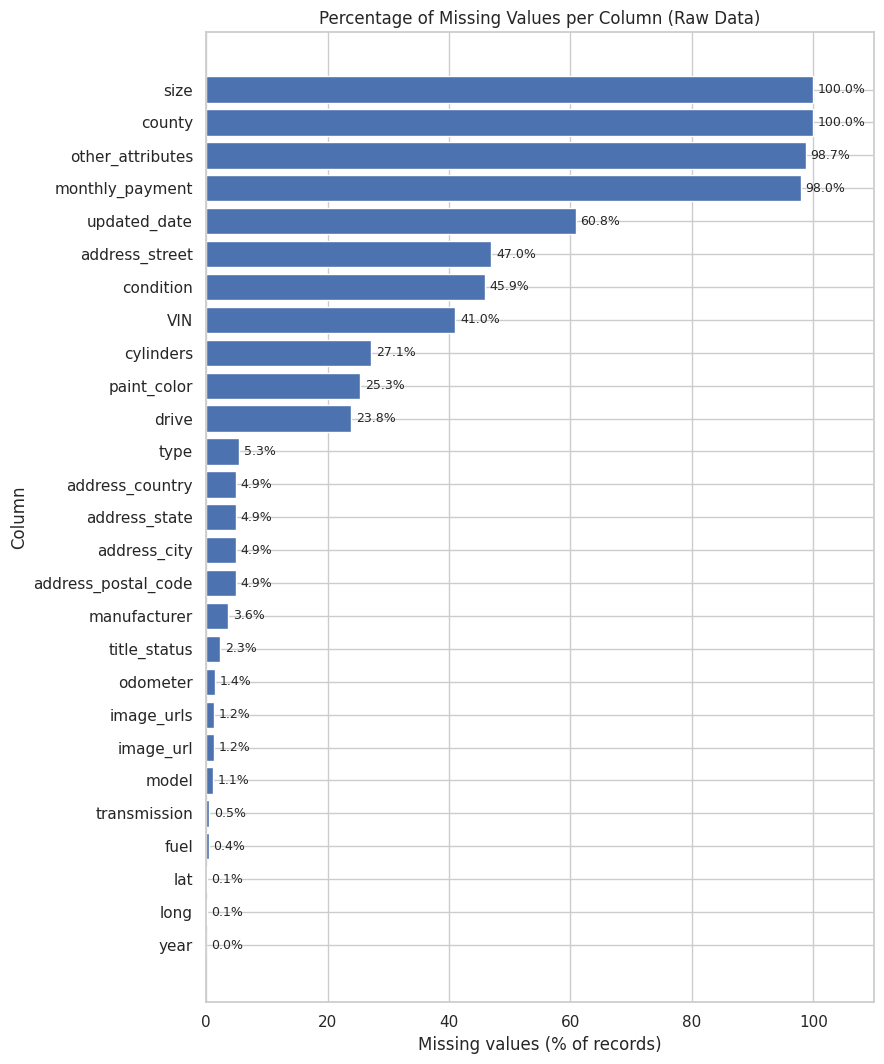

In [ ]:
# Visualisation: percentage of missing values per column
plot_data = missing_report[missing_report["Missing Percentage"] > 0].sort_values("Missing Percentage")

if plot_data.empty:
    print("No missing values to plot.")
else:
    fig, ax = plt.subplots(figsize=(9, max(3, 0.4 * len(plot_data))))
    ax.barh(plot_data["Column"], plot_data["Missing Percentage"], color="#4C72B0")
    for y, value in enumerate(plot_data["Missing Percentage"]):
        ax.text(value + 0.8, y, f"{value:.1f}%", va="center", fontsize=9)
    ax.set_xlim(0, 110)
    ax.set_title("Percentage of Missing Values per Column (Raw Data)")
    ax.set_xlabel("Missing values (% of records)")
    ax.set_ylabel("Column")
    plt.tight_layout()
    plt.show()

### Investigating the target variable `price`

The target must be handled with extra care. A record without a valid price **cannot teach a model anything**, and inventing a price (imputation) would create fake training labels. Missing, zero and negative prices are therefore counted separately.

In [ ]:
price_numeric = num("price")
price_original = S("price")

price_missing = int(price_original.isna().sum())
price_unparseable = int((price_original.notna() & price_numeric.isna()).sum())
price_zero = int((price_numeric == 0).sum())
price_negative = int((price_numeric < 0).sum())

price_investigation = pd.DataFrame({
    "Check": ["Missing price (NaN)", "Non-numeric price text", "Price equal to 0", "Negative price"],
    "Records": [price_missing, price_unparseable, price_zero, price_negative],
})
price_investigation["% of records"] = (price_investigation["Records"] / len(df_working) * 100).round(3)
display(price_investigation)

,Check,Records,% of records
0,Missing price (NaN),0,0.000
1,Non-numeric price text,0,0.000
2,Price equal to 0,10288,3.482
3,Negative price,0,0.000


### Missing-value treatment decisions (each variable evaluated individually)

| Variable(s) | Decision | Reason |
|---|---|---|
| `price` (target) | **Not imputed.** Records with missing, zero, negative or implausible price are excluded from `df_cleaned` (they stay in `df_raw`). | A supervised model needs genuine labels. Invented prices would corrupt the target. |
| `year`, `odometer` | **Not imputed in this stage.** Impossible values become missing; missing values are kept. | Median/mean imputation uses statistics learned from the data. If done on the full dataset, information from future test records would leak into training (**data leakage**). It should be done later *inside the training pipeline*, fitted on the training set only. |
| `manufacturer`, `model`, `condition`, `cylinders`, `fuel`, `title_status`, `transmission`, `drive`, `size`, `type`, `paint_color`, `state` | Replace missing with an explicit **`unknown`** category. | Mode imputation would claim every unknown car is the most common type (false information). "Unknown" is honest, learns nothing from the data (no leakage) and the fact that a seller left a field blank may itself be informative. |
| `lat`, `long` | Keep missing. | Coordinates are location-specific; filling them with a mean would place cars in the wrong place. |
| `VIN`, `description`, `posting_date` | Keep missing. | Optional/identifier fields; not required for Stage 3. |
| `county` | Remove **only if** completely empty. | An empty column carries no information. |

**Data-leakage note:** if mean/median/mode imputation, scaling or encoding is used in later stages, the statistic must be computed from the **training split only** and then applied to the validation/test data (for example inside a scikit-learn `Pipeline`). No statistic learned from the data is used in this notebook for filling values.

## 8. Duplicate Record Analysis

**What will happen?** We look for four kinds of repetition:
1. **Exact duplicates** – every column is identical (safe to remove).
2. **Duplicate IDs** – the same `id` appears more than once (may or may not be an exact copy).
3. **Duplicate listing URLs / VINs** – the same advertisement or car appears more than once.
4. **Repeated advertisements** – the same advert posted again (different `id`/`url`, but identical vehicle attributes, price **and advert text**). These are confirmed re-posts. Rows with the same attributes and price but a *different* advert text are only **similar listings**.

**Why?** Duplicated rows give the same car extra weight and make it more likely that a model sees test-like examples during training.

**Important:** exact duplicates and confirmed re-posts are removed. Rows that merely look similar may be genuine, different cars of the same model, so they are kept. Re-posts also matter for modelling: if the same advert were in both the training and the test set, the test score would be unrealistically good.

In [ ]:
n_total = len(df_working)

# 1. Exact duplicates (all columns identical)
exact_mask = df_working.duplicated(keep="first")
n_exact = int(exact_mask.sum())

# 2. Duplicate IDs
id_series = S("id")
if id_series is not None:
    n_dup_id = int(id_series.duplicated(keep="first").sum())
    n_dup_id_rows_involved = int(id_series.duplicated(keep=False).sum())
    n_dup_id_not_exact = n_dup_id - n_exact if n_dup_id >= n_exact else 0
else:
    n_dup_id = n_dup_id_rows_involved = n_dup_id_not_exact = None
    print("Column 'id' not found - duplicate-ID check skipped.")

# 3. Duplicate URLs and VINs
url_series, vin_series = S("url"), S("vin")
n_dup_url = int(url_series.dropna().duplicated().sum()) if url_series is not None else None
n_dup_vin = int(vin_series.dropna().duplicated().sum()) if vin_series is not None else None

# 4. Repeated advertisements
STRICT_KEY = ["year", "manufacturer", "model", "odometer", "price", "state", "description"]            # same advert re-posted
LOOSE_KEY = ["year", "manufacturer", "model", "odometer", "price", "state", "transmission", "fuel"]    # merely similar listings
strict_cols, loose_cols = present(STRICT_KEY), present(LOOSE_KEY)

confirmed_mask = pd.Series(False, index=df_working.index)
n_repeated_confirmed = n_similar_extra = None
if len(strict_cols) >= 5:
    confirmed_mask = df_working.duplicated(subset=strict_cols, keep="first") & ~exact_mask
    n_repeated_confirmed = int(confirmed_mask.sum())
if len(loose_cols) >= 5:
    similar_mask = df_working.duplicated(subset=loose_cols, keep="first") & ~exact_mask & ~confirmed_mask
    n_similar_extra = int(similar_mask.sum())
if n_repeated_confirmed is None or n_similar_extra is None:
    print("Not enough columns for the complete repeated-advertisement check.")

def pct(x):
    return None if x is None else round(x / n_total * 100, 3)

duplicate_report = pd.DataFrame([
    ["Exact duplicate rows (all columns identical)", n_exact, pct(n_exact), "REMOVE (keep first occurrence)"],
    ["Duplicate id values (rows beyond the first)", n_dup_id, pct(n_dup_id), "Exact copies removed; others investigated"],
    ["Duplicate id but rows NOT identical", n_dup_id_not_exact, pct(n_dup_id_not_exact), "KEEP and document (cannot be confirmed as duplicates)"],
    ["Duplicate listing url (non-missing)", n_dup_url, pct(n_dup_url), "Informational"],
    ["Duplicate VIN (non-missing)", n_dup_vin, pct(n_dup_vin), "KEEP - dealers may re-list; VIN text can be mistyped"],
    ["Confirmed re-posted adverts (same attributes, price AND advert text; not exact copies)", n_repeated_confirmed, pct(n_repeated_confirmed), "REMOVE (keep first posting)"],
    ["Similar listings (same attributes and price, different text)", n_similar_extra, pct(n_similar_extra), "KEEP - not confirmed as the same advert"],
], columns=["Check", "Records Identified", "% of Records", "Decision"])

print(f"Total records: {n_total:,}")
display(duplicate_report)

Total records: 295,451


,Check,Records Identified,% of Records,Decision
0,Exact duplicate rows (all columns identical),0,0.000,REMOVE (keep first occurrence)
1,Duplicate id values (rows beyond the first),0,0.000,Exact copies removed; others investigated
2,Duplicate id but rows NOT identical,0,0.000,KEEP and document (cannot be confirmed as duplicates)
3,Duplicate listing url (non-missing),0,0.000,Informational
4,Duplicate VIN (non-missing),84239,28.512,KEEP - dealers may re-list; VIN text can be mistyped
5,"Confirmed re-posted adverts (same attributes, price AND ...",47312,16.013,REMOVE (keep first posting)
6,"Similar listings (same attributes and price, different t...",39706,13.439,KEEP - not confirmed as the same advert


In [ ]:
# Show a sample of exact duplicate records (sorted so that copies sit next to each other)
sample_cols = present(["id", "region", "price", "year", "manufacturer", "model", "odometer", "posting_date"])
dup_rows = df_working[df_working.duplicated(keep=False)]

if dup_rows.empty:
    print("No exact duplicate records were found.")
else:
    sort_col = RAW.get("id", sample_cols[0])
    print("Sample of exact duplicate records (all copies shown):")
    display(dup_rows.sort_values(sort_col).head(10)[sample_cols])

# Sample of duplicate ids that are NOT exact copies
if id_series is not None and n_dup_id_not_exact > 0:
    dup_id_only = df_working[id_series.duplicated(keep=False) & ~df_working.duplicated(keep=False)]
    print("\nSample of rows sharing an id but differing in other columns:")
    display(dup_id_only.sort_values(RAW["id"]).head(10)[sample_cols])

No exact duplicate records were found.


### Interpretation – Section 8
- **Exact duplicates** are the same record stored more than once; removing them loses no information.
- **Duplicate IDs** that are *not* exact copies mean two different rows share an identifier. We cannot tell which is correct, so both are kept and the issue is documented.
- **Similar listings** (same attributes in different rows) are kept: two sellers can legitimately list the same model with the same year and mileage.
- The decision and the actual number of rows removed are recorded in the cleaning audit log (Section 13).

## 9. Inconsistent Values and Formats

**What will happen?** We look for the same real-world value written in different ways, and for numbers or dates stored in the wrong format.

**Why?** A model treats `Automatic`, `automatic ` and `AUTOMATIC` as three different categories unless they are standardised. We standardise **only values that are genuinely equivalent** and never merge different categories.

### 9.1 Categorical text consistency
For every categorical column we count:
- values with **leading/trailing spaces**,
- values that differ only by **capitalisation or repeated spaces**,
- **numeric-looking** values inside a text column (mixed numeric and text),
- how many distinct labels exist **before** and **after** a standard formatting rule (strip spaces, collapse repeated spaces, lowercase).

In [ ]:
def variant_report(series):
    """Describe text-format inconsistencies in one categorical column."""
    s = series.dropna().astype(str)
    stripped = s.str.strip()
    normalised = stripped.str.replace(r"\s+", " ", regex=True).str.lower()
    return {
        "non_missing": len(s),
        "values_with_extra_spaces": int((s != stripped).sum()),
        "values_differing_only_by_case_or_spacing": int((stripped != normalised).sum()),
        "numeric_looking_values": int(stripped.str.fullmatch(r"\d+(\.\d+)?").sum()),
        "unique_labels_raw": s.nunique(),
        "unique_labels_after_standard_format": normalised.nunique(),
    }

variant_rows = {}
for col in present(CAT_COLS):
    if is_text(df_working[col]):
        variant_rows[col] = variant_report(df_working[col])

consistency_table = pd.DataFrame(variant_rows).T
consistency_table["labels_that_would_merge"] = (consistency_table["unique_labels_raw"]
                                                - consistency_table["unique_labels_after_standard_format"])
print("Text-consistency check of the categorical columns:")
display(consistency_table)

Text-consistency check of the categorical columns:


,non_missing,values_with_extra_spaces,values_differing_only_by_case_or_spacing,numeric_looking_values,unique_labels_raw,unique_labels_after_standard_format,labels_that_would_merge
region,295451,0,31267,0,400,400,0
manufacturer,284659,0,0,0,42,42,0
model,292092,0,8097,7630,27958,27173,785
condition,159961,0,0,0,6,6,0
cylinders,215284,0,0,0,8,8,0
fuel,294320,0,0,0,5,5,0
title_status,288635,0,0,0,6,6,0
transmission,293895,0,0,0,3,3,0
drive,225076,0,0,0,3,3,0
type,279642,0,89345,0,13,13,0


In [ ]:
# Display the unique values of the small categorical columns so that we can inspect them by eye
LISTING_LIMIT = 60
for col in present(["manufacturer", "condition", "fuel", "transmission", "cylinders", "title_status",
                    "drive", "size", "type", "paint_color"]):
    uniques = sorted(df_working[col].dropna().astype(str).unique())
    shown = uniques[:LISTING_LIMIT]
    extra = f" ... (+{len(uniques) - LISTING_LIMIT} more)" if len(uniques) > LISTING_LIMIT else ""
    print(f"\n[{col}] {len(uniques)} unique values:\n{shown}{extra}")


[manufacturer] 42 unique values:
['acura', 'alfa-romeo', 'aston-martin', 'audi', 'bmw', 'buick', 'cadillac', 'chevrolet', 'chrysler', 'datsun', 'dodge', 'ferrari', 'fiat', 'ford', 'gmc', 'harley-davidson', 'honda', 'hyundai', 'infiniti', 'jaguar', 'jeep', 'kia', 'land rover', 'lexus', 'lincoln', 'mazda', 'mercedes-benz', 'mercury', 'mini', 'mitsubishi', 'morgan', 'nissan', 'pontiac', 'porsche', 'ram', 'rover', 'saturn', 'subaru', 'tesla', 'toyota', 'volkswagen', 'volvo']

[condition] 6 unique values:
['excellent', 'fair', 'good', 'like new', 'new', 'salvage']

[fuel] 5 unique values:
['diesel', 'electric', 'gas', 'hybrid', 'other']

[transmission] 3 unique values:
['automatic', 'manual', 'other']

[cylinders] 8 unique values:
['10 cylinders', '12 cylinders', '3 cylinders', '4 cylinders', '5 cylinders', '6 cylinders', '8 cylinders', 'other']

[title_status] 6 unique values:
['clean', 'lien', 'missing', 'parts only', 'rebuilt', 'salvage']

[drive] 3 unique values:
['4wd', 'fwd', 'rwd']


In [ ]:
# Specific example: do 'automatic', 'Automatic', 'AUTOMATIC' occur as separate categories?
trans = S("transmission")
if trans is not None:
    labels = trans.dropna().astype(str).str.strip()
    groups = labels.groupby(labels.str.lower()).nunique()
    conflicting = groups[groups > 1]
    print("Transmission labels that differ only by capitalisation:",
          list(conflicting.index) if len(conflicting) else "none - capitalisation is already consistent")

# State codes should be exactly two letters
state = S("state")
if state is not None:
    bad_state = state.dropna().astype(str).str.strip()
    bad_state = bad_state[~bad_state.str.fullmatch(r"[A-Za-z]{2}")]
    print(f"State values that are not a 2-letter code: {len(bad_state)}  {sorted(bad_state.unique())[:10]}")

Transmission labels that differ only by capitalisation: none - capitalisation is already consistent
State values that are not a 2-letter code: 0  []


### 9.2 Numerical format checks
`price`, `year`, `odometer`, `lat` and `long` should be numeric. If pandas imported any of them as text (`object`/`string`), some entries are not valid numbers. The next cell counts entries that **cannot be converted**, without changing `df_working`. They are converted only in Section 13, after this assessment.

In [ ]:
numeric_rows = []
for std in ["price", "year", "odometer", "lat", "long"]:
    original = S(std)
    if original is None:
        print(f"Column '{std}' not found - skipped.")
        continue
    converted = to_number(original)
    unparseable_mask = original.notna() & converted.isna()
    numeric_rows.append({
        "Column": RAW[std], "Imported dtype": str(original.dtype),
        "Is numeric dtype": pd.api.types.is_numeric_dtype(original),
        "Non-missing values": int(original.notna().sum()),
        "Values that cannot be converted to numbers": int(unparseable_mask.sum()),
        "Examples of unconvertible values": list(original[unparseable_mask].astype(str).unique()[:5]),
    })

numeric_format_check = pd.DataFrame(numeric_rows)
display(numeric_format_check)

,Column,Imported dtype,Is numeric dtype,Non-missing values,Values that cannot be converted to numbers,Examples of unconvertible values
0,price,object,False,295451,0,[]
1,year,float64,True,295425,0,[]
2,odometer,float64,True,291415,0,[]
3,lat,float64,True,295302,0,[]
4,long,float64,True,295302,0,[]


### 9.3 Date and time format check (`posting_date`)
The date is parsed with a robust method: records that fail to parse become "not a time" (`NaT`) in the *converted* column, but **nothing is dropped** and the original text stays in the raw data. The number of successes and failures is reported.

In [ ]:
PANDAS_MAJOR = int(pd.__version__.split(".")[0])

def parse_dates(series):
    """Parse date text to timezone-aware UTC datetimes. Failures become NaT (never dropped)."""
    if PANDAS_MAJOR >= 2:
        parsed = pd.to_datetime(series, errors="coerce", utc=True, format="ISO8601")
        retry = parsed.isna() & series.notna()
        if retry.any():                     # second attempt with flexible parsing for non-ISO text
            parsed.loc[retry] = pd.to_datetime(series[retry], errors="coerce", utc=True)
        return parsed
    return pd.to_datetime(series, errors="coerce", utc=True)

date_series = S("posting_date")
if date_series is None:
    print("Column 'posting_date' not found - date checks skipped.")
else:
    parsed_dates = parse_dates(date_series)
    n_with_value = int(date_series.notna().sum())
    n_parsed = int(parsed_dates.notna().sum())
    n_failed = n_with_value - n_parsed
    print(f"Records with a posting_date value : {n_with_value:,}")
    print(f"Successfully converted            : {n_parsed:,}")
    print(f"Failed to convert                 : {n_failed:,}")
    if n_failed:
        print("Examples of values that failed:", list(date_series[date_series.notna() & parsed_dates.isna()].astype(str).unique()[:5]))
    if n_parsed:
        print(f"Earliest posting date: {parsed_dates.min()}")
        print(f"Latest posting date  : {parsed_dates.max()}")

Records with a posting_date value : 295,451
Successfully converted            : 295,451
Failed to convert                 : 0
Earliest posting date: 2026-09-30 07:17:53+00:00
Latest posting date  : 2026-11-03 04:41:25+00:00


### Interpretation – Section 9
- `labels_that_would_merge` > 0 means different spellings/capitalisations of the *same* label exist and standardisation is justified; a value of 0 means the column is already consistent (no change will be made).
- Numeric columns with non-convertible entries need a conversion step that turns invalid text into a missing value **and reports how many** were affected.
- The range of posting dates shows the **data-collection period**, which we use in Section 10 to decide which vehicle years are impossible.

## 10. Invalid and Impossible Value Detection

**What will happen?** We apply domain rules to find values that are logically impossible or implausible, and count them.

**Why?** An invalid value (a price of $0, an odometer of -5, a year in the future) is an error, not an unusual-but-real observation. We separate the two carefully: *a very expensive car may be real, a negative mileage cannot be.*

### Thresholds used (assumptions – you may edit them)
| Setting | Value | Reasoning |
|---|---|---|
| `PRICE_MAX_PLAUSIBLE` | 1,000,000 | Used-car listings of $1 million or more are overwhelmingly typing errors or placeholders (e.g. 1234567890). Rare real exotic cars above this level are accepted as a small, documented loss. |
| `PRICE_LOW_REVIEW` | 500 | Prices of $1–$499 are *suspicious* (down-payments, "call me" prices) but cannot be proven invalid, so they are **kept and flagged**. |
| `YEAR_MIN_VALID` | 1900 | The first mass-produced cars date from around 1900. |
| `MAX_VALID_YEAR` | collection year + 1 | Manufacturers sell next-year models; the collection year is taken from `posting_date`. |
| `ODOMETER_MAX_PLAUSIBLE` | 1,000,000 miles | Beyond this, values are almost certainly data-entry errors/placeholders. |
| US coordinate box | lat 17–72, long -180 to -64 | Covers all US states, territories and Alaska/Hawaii. The dataset is US-only. |

In [ ]:
# ----------------------- Domain-rule thresholds (editable) -----------------------
PRICE_MAX_PLAUSIBLE = 1_000_000
PRICE_LOW_REVIEW = 500
YEAR_MIN_VALID = 1900
ODOMETER_MAX_PLAUSIBLE = 1_000_000
US_LAT_RANGE = (17.0, 72.0)
US_LON_RANGE = (-180.0, -64.0)
# ---------------------------------------------------------------------------------

# Data-collection year: latest posting year that is not in the future
if S("posting_date") is not None and parsed_dates.notna().any():
    usable_dates = parsed_dates[parsed_dates <= pd.Timestamp.now(tz="UTC")]
    DATA_COLLECTION_YEAR = int(usable_dates.dt.year.max())
    print(f"Data-collection year derived from posting_date: {DATA_COLLECTION_YEAR}")
else:
    DATA_COLLECTION_YEAR = datetime.now().year
    print(f"posting_date unavailable - using the current year instead: {DATA_COLLECTION_YEAR}")
MAX_VALID_YEAR = DATA_COLLECTION_YEAR + 1
print(f"Valid vehicle years: {YEAR_MIN_VALID} to {MAX_VALID_YEAR}")

price_n, year_n, odo_n = num("price"), num("year"), num("odometer")
lat_n, lon_n = num("lat"), num("long")

rules = []
def add_rule(column, rule, mask, treatment):
    count = int(mask.sum())
    rules.append({"Column": column, "Rule": rule, "Records": count,
                  "% of records": round(count / len(df_working) * 100, 3), "Planned treatment": treatment})

add_rule("price", "Missing", price_n.isna(), "Exclude record from cleaned data")
add_rule("price", "Zero or negative (<= 0)", price_n <= 0, "Exclude record from cleaned data")
add_rule("price", f"Implausibly high (>= {PRICE_MAX_PLAUSIBLE:,})", price_n >= PRICE_MAX_PLAUSIBLE, "Exclude record from cleaned data")
add_rule("price", f"Suspiciously low (1 to {PRICE_LOW_REVIEW - 1})", (price_n > 0) & (price_n < PRICE_LOW_REVIEW), "Keep, add review flag")
add_rule("price", f"High but plausible ({PRICE_MAX_PLAUSIBLE // 2:,} to {PRICE_MAX_PLAUSIBLE - 1:,})", (price_n >= PRICE_MAX_PLAUSIBLE // 2) & (price_n < PRICE_MAX_PLAUSIBLE), "Keep (may be a genuine exotic vehicle)")
add_rule("year", "Missing", year_n.isna(), "Keep as missing")
add_rule("year", f"Before {YEAR_MIN_VALID}", year_n < YEAR_MIN_VALID, "Set to missing")
add_rule("year", f"After {MAX_VALID_YEAR} (future)", year_n > MAX_VALID_YEAR, "Set to missing")
add_rule("odometer", "Missing", odo_n.isna(), "Keep as missing")
add_rule("odometer", "Negative", odo_n < 0, "Set to missing")
add_rule("odometer", f"Above {ODOMETER_MAX_PLAUSIBLE:,} miles", odo_n > ODOMETER_MAX_PLAUSIBLE, "Set to missing")
add_rule("odometer", "Exactly 0 (possible placeholder or new vehicle)", odo_n == 0, "Keep (cannot be proven invalid)")
add_rule("lat", "Missing", lat_n.isna(), "Keep as missing")
add_rule("lat", "Outside -90 to 90 (impossible)", (lat_n < -90) | (lat_n > 90), "Set lat and long to missing")
add_rule("long", "Missing", lon_n.isna(), "Keep as missing")
add_rule("long", "Outside -180 to 180 (impossible)", (lon_n < -180) | (lon_n > 180), "Set lat and long to missing")
outside_us = ((lat_n.notna() & ((lat_n < US_LAT_RANGE[0]) | (lat_n > US_LAT_RANGE[1])))
              | (lon_n.notna() & ((lon_n < US_LON_RANGE[0]) | (lon_n > US_LON_RANGE[1]))))
add_rule("lat / long", "Outside the US bounding box (dataset is US-only)", outside_us, "Set lat and long to missing")

state_s = S("state")
if state_s is not None:
    bad_state_mask = state_s.notna() & ~state_s.astype(str).str.strip().str.fullmatch(r"[A-Za-z]{2}")
    add_rule("state", "Not a 2-letter code", bad_state_mask, "Set to missing, then 'unknown'")

placeholder_total = sum(v for k, v in hidden_missing.items())
rules.append({"Column": "text columns", "Rule": "Blank strings / placeholder labels (e.g. 'n/a')", "Records": placeholder_total,
              "% of records": np.nan, "Planned treatment": "Convert to missing, then treat as missing"})

invalid_rules_table = pd.DataFrame(rules)
print("Invalid and impossible value checks (raw data):")
display(invalid_rules_table)

Data-collection year derived from posting_date: 2026
Valid vehicle years: 1900 to 2027
Invalid and impossible value checks (raw data):


,Column,Rule,Records,% of records,Planned treatment
0,price,Missing,0,0.000,Exclude record from cleaned data
1,price,Zero or negative (<= 0),10288,3.482,Exclude record from cleaned data
2,price,"Implausibly high (>= 1,000,000)",73,0.025,Exclude record from cleaned data
3,price,Suspiciously low (1 to 499),2365,0.800,"Keep, add review flag"
4,price,"High but plausible (500,000 to 999,999)",14,0.005,Keep (may be a genuine exotic vehicle)
5,year,Missing,26,0.009,Keep as missing
6,year,Before 1900,0,0.000,Set to missing
7,year,After 2027 (future),0,0.000,Set to missing
8,odometer,Missing,4036,1.366,Keep as missing
9,odometer,Negative,0,0.000,Set to missing


### Interpretation – Section 10
Every row of the table is a rule applied to the real data. Records counted as *impossible* (negative mileage, coordinates outside the valid range, zero price) are **errors**. Records counted as *implausible* (very high price or mileage) are removed or blanked only where the threshold above justifies it. Values that are merely *unusual* (high but plausible prices, odometer 0, low prices) are **kept** and – where useful – flagged for review in Stage 4.

## 11. Outlier Detection

**What will happen?** We search for statistically extreme values in `price`, `year`, `odometer`, `lat` and `long` using descriptive statistics, quartiles, the **Interquartile Range (IQR)** rule and boxplots.

**The IQR rule**

- IQR = Q3 − Q1 (the spread of the middle 50% of the data)
- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR

Values outside the bounds are *statistical outliers*. **They are not automatically errors:** a luxury car has a legitimately high price, a delivery truck can have very high mileage, and a classic car can be 80 years old. Therefore the bounds are calculated on values that already pass the domain rules of Section 10 (so that placeholders such as a $3 billion price do not distort the quartiles), and IQR outliers are **retained and flagged**, not deleted.

In [ ]:
# Domain-valid values only (so that impossible placeholders do not distort the quartiles)
price_valid = price_n[(price_n > 0) & (price_n < PRICE_MAX_PLAUSIBLE)].dropna()
year_valid = year_n[(year_n >= YEAR_MIN_VALID) & (year_n <= MAX_VALID_YEAR)].dropna()
odo_valid = odo_n[(odo_n >= 0) & (odo_n <= ODOMETER_MAX_PLAUSIBLE)].dropna()
lat_valid = lat_n[(lat_n >= US_LAT_RANGE[0]) & (lat_n <= US_LAT_RANGE[1])].dropna()
lon_valid = lon_n[(lon_n >= US_LON_RANGE[0]) & (lon_n <= US_LON_RANGE[1])].dropna()

def iqr_summary(series, name):
    """IQR boundaries and outlier counts for one numeric series."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    below, above = int((series < lower).sum()), int((series > upper).sum())
    return {"Variable": name, "Valid values used": len(series), "Min": series.min(), "Q1": q1, "Median": series.median(),
            "Q3": q3, "Max": series.max(), "IQR": iqr, "Lower bound": lower, "Upper bound": upper,
            "Below lower bound": below, "Above upper bound": above,
            "Outliers (% of valid)": round((below + above) / len(series) * 100, 2)}

series_list = [(price_valid, "price"), (year_valid, "year"), (odo_valid, "odometer"), (lat_valid, "lat"), (lon_valid, "long")]
iqr_table = pd.DataFrame([iqr_summary(s, n) for s, n in series_list if len(s) > 0])
print("IQR boundaries and number of statistical outliers (calculated from the actual data):")
display(iqr_table.round(2))

IQR boundaries and number of statistical outliers (calculated from the actual data):


,Variable,Valid values used,Min,Q1,Median,Q3,Max,IQR,Lower bound,Upper bound,Below lower bound,Above upper bound,Outliers (% of valid)
0,price,285090,1.00,6950.00,12995.00,22995.00,999999.00,16045.00,-17117.50,47062.50,0,17058,5.98
1,year,295425,1900.00,2010.00,2015.00,2019.00,2027.00,9.00,1996.50,2032.50,16326,0,5.53
2,odometer,291128,1.00,67579.50,107419.00,147180.00,1000000.00,79600.50,-51821.25,266580.75,0,4661,1.60
3,lat,295298,19.09,34.06,38.85,43.60,64.99,9.53,19.76,57.90,372,1624,0.68
4,long,295299,-159.72,-121.47,-110.96,-84.46,-67.26,37.01,-176.98,-28.94,0,0,0.00


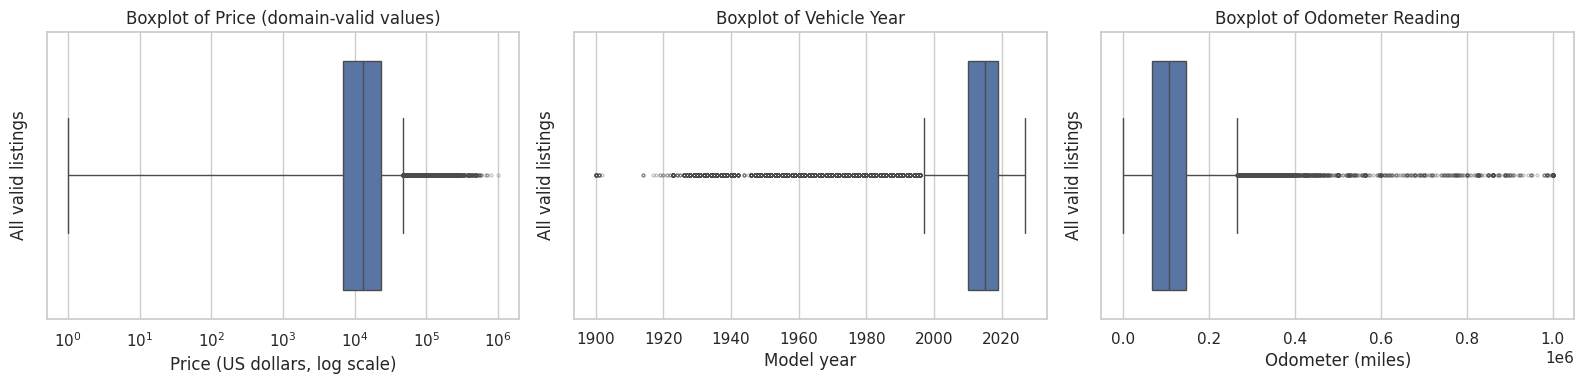

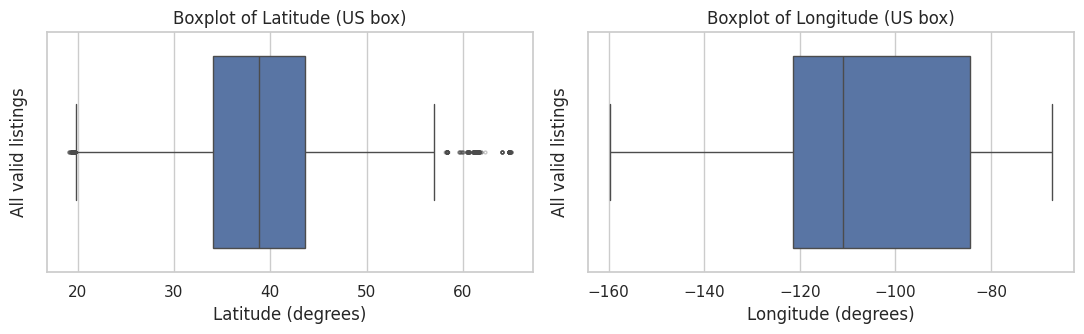

In [ ]:
# Boxplots (price uses a logarithmic axis because prices are very right-skewed)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
box_style = dict(flierprops=dict(markersize=2, alpha=0.3), color="#4C72B0")

sns.boxplot(x=price_valid, ax=axes[0], **box_style)
axes[0].set_xscale("log")
axes[0].set_title("Boxplot of Price (domain-valid values)")
axes[0].set_xlabel("Price (US dollars, log scale)")
axes[0].set_ylabel("All valid listings")

sns.boxplot(x=year_valid, ax=axes[1], **box_style)
axes[1].set_title("Boxplot of Vehicle Year")
axes[1].set_xlabel("Model year")
axes[1].set_ylabel("All valid listings")

sns.boxplot(x=odo_valid, ax=axes[2], **box_style)
axes[2].set_title("Boxplot of Odometer Reading")
axes[2].set_xlabel("Odometer (miles)")
axes[2].set_ylabel("All valid listings")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.boxplot(x=lat_valid, ax=axes[0], **box_style)
axes[0].set_title("Boxplot of Latitude (US box)")
axes[0].set_xlabel("Latitude (degrees)")
axes[0].set_ylabel("All valid listings")
sns.boxplot(x=lon_valid, ax=axes[1], **box_style)
axes[1].set_title("Boxplot of Longitude (US box)")
axes[1].set_xlabel("Longitude (degrees)")
axes[1].set_ylabel("All valid listings")
plt.tight_layout()
plt.show()

### Investigating extreme prices separately
Before deciding anything, we look at the most expensive and the cheapest **domain-valid** records and at the upper percentiles to judge whether the extremes look like genuine vehicles.

In [ ]:
detail_cols = present(["id", "region", "price", "year", "manufacturer", "model", "odometer", "condition", "type"])

print("Price percentiles (domain-valid prices):")
display(price_valid.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]).round(0).to_frame("price"))

print("\nTen highest domain-valid prices - do they look like real vehicles?")
display(df_working.loc[price_valid.nlargest(10).index, detail_cols])

print("\nTen lowest domain-valid prices:")
display(df_working.loc[price_valid.nsmallest(10).index, detail_cols])

Price percentiles (domain-valid prices):


,price
0.010,500.0
0.050,2500.0
0.250,6950.0
0.500,12995.0
0.750,22995.0
0.950,49997.0
0.990,89900.0
0.999,219988.0



Ten highest domain-valid prices - do they look like real vehicles?


,id,region,price,year,manufacturer,model,odometer,condition,type
230539,7978705326,salem,999999,2022.0,toyota,camry,114000.0,excellent,sedan
85167,7986809205,ft myers / SW florida,799000,2024.0,mercedes-benz,amg g 63,656.0,NaN,SUV
117533,7977678108,las vegas,700000,2006.0,ford,gt,2500.0,excellent,coupe
227863,7977678219,sacramento,700000,2006.0,ford,gt,2500.0,excellent,coupe
214440,7993861077,rhode island,654321,1949.0,mercury,NaN,1111111.0,good,NaN
59153,7985838420,dallas / fort worth,589980,2022.0,ferrari,f8 spider,8767.0,like new,convertible
262388,7985838744,south florida,589980,2022.0,ferrari,f8 spider,8767.0,like new,convertible
261480,7989108300,south florida,560900,2026.0,NaN,rolls-royce cullinan,747.0,like new,SUV
65054,7989423465,denver,555555,1970.0,NaN,plymouth cuda,555555.0,NaN,convertible
60611,7978750038,dallas / fort worth,549980,2018.0,ferrari,812 superfast,9900.0,like new,coupe



Ten lowest domain-valid prices:


,id,region,price,year,manufacturer,model,odometer,condition,type
1146,7993198464,SF bay area,1,2022.0,toyota,sienna we buy wheelchair vans,1000.0,NaN,mini-van
1697,7992828063,SF bay area,1,2025.0,lexus,es,1.0,excellent,sedan
2828,7992175497,SF bay area,1,1997.0,bmw,318ti,239000.0,excellent,hatchback
2833,7992163782,SF bay area,1,1994.0,NaN,Lancia Delta Integrale EVO II,39800.0,NaN,NaN
4962,7989873111,SF bay area,1,2011.0,audi,a4,129000.0,good,sedan
5363,7989355671,SF bay area,1,1999.0,toyota,corolla,165000.0,NaN,sedan
6839,7988108433,SF bay area,1,2017.0,toyota,camry,10000.0,good,sedan
7616,7987228953,SF bay area,1,2010.0,nissan,cube,170500.0,good,wagon
7683,7987129032,SF bay area,1,2013.0,ford,fusion se,188753.0,NaN,sedan
7684,7987126257,SF bay area,1,2008.0,porsche,cayenne,135000.0,NaN,SUV


### Outlier decisions and reasons
| Variable | Decision | Reason |
|---|---|---|
| `price` | **Remove** only invalid/implausible prices (missing, ≤ 0, ≥ the plausibility cap) – already defined in Section 10. IQR outliers are **retained** and receive a flag column `flag_price_iqr_outlier`. Prices below the review level receive `flag_low_price`. | Luxury, classic and exotic vehicles are genuinely expensive. Deleting every IQR outlier would remove real market segments and bias the future model toward cheap cars. |
| `year` | Impossible years (before 1900 / after the allowed year) become missing. Old-but-valid years are **retained** with `flag_year_iqr_outlier`. | Classic cars are legitimately sold. |
| `odometer` | Negative and implausibly high values become missing. Other IQR outliers are **retained** with `flag_odometer_iqr_outlier`. | Commercial vehicles can have very high mileage. |
| `lat`, `long` | Outside the valid / US range → both coordinates set to missing. | Coordinates outside the US contradict the dataset's coverage. |
| Further action | Stage 4 may consider a log-transformation of `price`, capping/winsorising or a robust model. | Such choices depend on the modelling approach and belong to Stage 4, not to data cleaning. |

## 12. Irrelevant and Redundant Column Assessment

**What will happen?** Every column is evaluated for usefulness and given a decision: *retain*, *retain for traceability but exclude from predictive features*, *investigate further*, or *remove*.

**Why?** Deleting columns just because they are not immediately useful destroys evidence. For example, `id` and the URLs are useless as predictors but valuable for tracing a cleaned record back to the raw data.

**Rule used for removal:** a column is removed **only if it is completely empty** (no information at all). All others are kept, and identifier-type columns are marked "exclude from future predictive features".

In [ ]:
ORIGINAL_COLUMNS = list(df_raw.columns)       # copy of the original column list (preserved)

COLUMN_ASSESSMENT = {
    "id": ("Identifier", "Record tracking key; may repeat", "Retain; exclude from predictive features", "Needed to trace cleaned records back to the raw file. An ID number carries no information about price."),
    "url": ("Identifier", "Long text, unique per listing", "Retain for traceability; exclude from features", "Lets a reader open the original advert. Not a vehicle attribute."),
    "region_url": ("Administrative", "Redundant with region", "Retain for traceability; exclude from features", "Same information as region in link form."),
    "vin": ("Identifier", "Mostly missing; unique per vehicle", "Retain for traceability; exclude from features", "A VIN is a unique identifier (one value per car), so a model would memorise it rather than learn. It could be decoded into make/model/year later, but only with an external decoder."),
    "image_url": ("Administrative / media", "Link to an image", "Retain; exclude from features", "Image analysis is outside the project scope."),
    "county": ("Geographic", "Documented column that is expected to be empty", "Remove only if completely empty", "A completely empty column holds no information; removal is recorded in the audit log."),
    "description": ("Optional text", "Free text, long, may contain personal details", "Retain; investigate further in Stage 4", "May contain useful vehicle details (e.g. 'new tires'), but needs text processing that belongs to Stage 4."),
    "posting_date": ("Time", "Stored as text in the raw data", "Retain; convert to datetime", "Defines the data-collection period; could support time features."),
    "price": ("Target", "Invalid/missing values exist", "Retain; clean carefully", "Target variable of the project."),
}
for c in ["year", "manufacturer", "model", "condition", "cylinders", "fuel", "odometer", "title_status",
          "transmission", "drive", "size", "type", "paint_color"]:
    COLUMN_ASSESSMENT[c] = ("Predictive attribute", "Check consistency / missing values", "Retain", "Describes the vehicle and is likely related to price.")
for c in ["region", "state", "lat", "long"]:
    COLUMN_ASSESSMENT[c] = ("Geographic", "Check validity / missing values", "Retain", "Location influences market price.")
COLUMN_ASSESSMENT["seller_type"] = ("Predictive attribute", "Check consistency / missing values", "Retain", "Dealers and private sellers price differently, and the seller type is known when a user asks for a price.")
COLUMN_ASSESSMENT["title"] = ("Optional text", "Free text", "Retain; exclude from features", "Overlaps with make, model and year.")
COLUMN_ASSESSMENT["updated_date"] = ("Administrative", "Date stored as text", "Retain; exclude from features", "Not a vehicle attribute.")
COLUMN_ASSESSMENT["address_street"] = ("Personal / identifying", "Contains street addresses", "Retain only in the private cleaned file; exclude from features and from every public file", "Privacy: personal data must not be published or used as a predictor.")
for c in ["address_city", "address_state", "address_postal_code", "address_country"]:
    COLUMN_ASSESSMENT[c] = ("Geographic (address)", "High cardinality or redundant with state; possibly identifying", "Retain; exclude from features and public files", "Overlaps with state/region; privacy risk.")
for c in ["image_count", "image_urls", "delivery_available"]:
    COLUMN_ASSESSMENT[c] = ("Listing metadata", "Created by the seller; not available to a user asking for a price", "Retain; exclude from features", "Cannot be provided in the deployed app.")
for c in ["odometer_broken", "odometer_rolled_over"]:
    COLUMN_ASSESSMENT[c] = ("Data-quality flag", "May explain unreliable odometer values", "Retain; investigate further", "Could be used to treat odometer readings with care.")
for c in ["monthly_payment", "other_attributes"]:
    COLUMN_ASSESSMENT[c] = ("Mostly empty / optional", "Heavily missing or free text", "Retain; exclude from features", "Little usable information.")

assessment_rows = []
for std, actual in RAW.items():
    relevance, concern, decision, justification = COLUMN_ASSESSMENT.get(
        std, ("Not documented", "Unknown column", "Investigate further", "Column is not in the documented list."))
    miss_pct = df_working[actual].isna().mean() * 100
    if miss_pct == 100:
        decision, concern = "Remove (completely empty)", f"{concern}; 100% missing"
    else:
        concern = f"{concern}; {miss_pct:.1f}% missing"
    assessment_rows.append({"Column": actual, "Relevance": relevance, "Data Quality Concern": concern,
                            "Decision": decision, "Justification": justification})

column_assessment = pd.DataFrame(assessment_rows)
print("Column assessment table:")
display(column_assessment)
print(f"\nColumns to be removed: {column_assessment.loc[column_assessment['Decision'].str.startswith('Remove'), 'Column'].tolist() or 'none'}")

Column assessment table:


,Column,Relevance,Data Quality Concern,Decision,Justification
0,id,Identifier,Record tracking key; may repeat; 0.0% missing,Retain; exclude from predictive features,Needed to trace cleaned records back to the raw file. An...
1,url,Identifier,"Long text, unique per listing; 0.0% missing",Retain for traceability; exclude from features,Lets a reader open the original advert. Not a vehicle at...
2,region,Geographic,Check validity / missing values; 0.0% missing,Retain,Location influences market price.
3,region_url,Administrative,Redundant with region; 0.0% missing,Retain for traceability; exclude from features,Same information as region in link form.
4,price,Target,Invalid/missing values exist; 0.0% missing,Retain; clean carefully,Target variable of the project.
5,year,Predictive attribute,Check consistency / missing values; 0.0% missing,Retain,Describes the vehicle and is likely related to price.
6,manufacturer,Predictive attribute,Check consistency / missing values; 3.7% missing,Retain,Describes the vehicle and is likely related to price.
7,model,Predictive attribute,Check consistency / missing values; 1.1% missing,Retain,Describes the vehicle and is likely related to price.
8,condition,Predictive attribute,Check consistency / missing values; 45.9% missing,Retain,Describes the vehicle and is likely related to price.
9,cylinders,Predictive attribute,Check consistency / missing values; 27.1% missing,Retain,Describes the vehicle and is likely related to price.



Columns to be removed: ['size', 'county']


### Interpretation – Section 12
Only completely empty columns are removed. Identifier and administrative columns stay in the cleaned file for traceability but are marked as **not to be used as predictive features** in later stages. The original column list is preserved in `ORIGINAL_COLUMNS`.

## 13. Data Cleaning Implementation

**What will happen?** All decisions from Sections 7–12 are applied step by step to a copy of the data (`df_cleaned`). Each step writes one or more lines to an **audit log** using the *actual* number of records/values affected.

**Why the order matters**
1. Rename columns, so later code refers to consistent names.
2. Remove exact duplicates first, so later steps do not process repeated rows.
3. Fix blanks, placeholders and text formatting.
4. Convert data types (invalid text becomes missing and is counted).
5. Handle the invalid *target* (price) – exclude those records.
6. Set impossible numeric values to missing.
7. Treat missing values (explicit `unknown` category; empty columns removed).
8. Flag statistical outliers (retained, not deleted).
9. Final tidy-up of data types.

`df_working` and `df_raw` are **not** touched; the work happens on `df_cleaned`.

In [ ]:
audit_log = []
counters = {"values_standardised": 0, "missing_values_treated": 0, "invalid_values_set_to_missing": 0}

def log_step(step, column, issue, action, affected, reason):
    """Add one line to the cleaning audit log (numbers come from real execution)."""
    audit_log.append({"Step": step, "Column": column, "Issue": issue, "Action": action,
                      "Records/Values Affected": int(affected), "Reason": reason})

df_cleaned = df_working.copy(deep=True)
print(f"Cleaning starts from {len(df_cleaned):,} records and {df_cleaned.shape[1]} columns.")

# ---- Step 1: standardise column names ----
rename_map = {c: std_name(c) for c in df_cleaned.columns}
renamed = {old: new for old, new in rename_map.items() if old != new}
df_cleaned = df_cleaned.rename(columns=rename_map)
assert df_cleaned.columns.is_unique, "Renaming produced duplicate column names."
log_step(1, "column names", "Inconsistent capitalisation / spaces in names",
         f"Renamed to lowercase_with_underscores: {renamed if renamed else 'no change needed'}", len(renamed),
         "Consistent names avoid errors and make code easier to read")

# ---- Step 2: remove exact duplicate rows ----
duplicate_mask = df_cleaned.duplicated(keep="first")
removed_duplicates = int(duplicate_mask.sum())
df_cleaned = df_cleaned.loc[~duplicate_mask]
log_step(2, "all columns", "Exact duplicate rows", "Removed repeated rows (first occurrence kept)", removed_duplicates,
         "Identical rows add no information and over-weight some listings")
print(f"Step 2 done: {removed_duplicates:,} exact duplicate rows removed.")

duplicate_report.loc[len(duplicate_report)] = ["Exact duplicates ACTUALLY removed in cleaning", removed_duplicates,
                                               round(removed_duplicates / n_total * 100, 3), "Executed in Section 13"]

Cleaning starts from 295,451 records and 41 columns.
Step 2 done: 0 exact duplicate rows removed.


In [ ]:
# ---- Step 3: blanks, placeholders and text standardisation ----
def standardise_text(series, lower=True, placeholders=None):
    """Strip spaces, collapse repeated spaces, optionally lowercase; placeholder labels become missing."""
    cleaned = series.copy()
    mask = series.notna()
    text = series[mask].astype(str).str.strip().str.replace(r"\s+", " ", regex=True)
    if lower:
        text = text.str.lower()
    cleaned.loc[mask] = text
    if placeholders:
        cleaned.loc[mask & cleaned.isin(placeholders)] = np.nan
    return cleaned

for col in CAT_COLS:
    if col not in df_cleaned.columns or not is_text(df_cleaned[col]):
        continue
    before = df_cleaned[col]
    after = standardise_text(before, lower=(col != "region"), placeholders=PLACEHOLDERS)   # region keeps its capitalisation (names)
    to_missing = int((before.notna() & after.isna()).sum())
    reformatted = int((before.notna() & after.notna() & (before != after)).sum())
    df_cleaned[col] = after
    counters["values_standardised"] += reformatted
    counters["missing_values_treated"] += 0
    log_step(3, col, "Spaces / capitalisation / placeholder labels",
             "Stripped spaces, collapsed repeated spaces, " + ("kept capitalisation, " if col == "region" else "lowercased, ") + "placeholder labels -> missing",
             reformatted + to_missing, f"{reformatted:,} values reformatted; {to_missing:,} placeholders set to missing; equivalent labels get one spelling")

# Other text columns: only blank strings become missing (no other change to the text)
blank_summary = {}
for col in df_cleaned.columns:
    if col in CAT_COLS or col == "posting_date" or not is_text(df_cleaned[col]):
        continue
    series = df_cleaned[col]
    blank = series.notna() & series.astype(str).str.strip().eq("")
    if blank.any():
        df_cleaned.loc[blank, col] = np.nan
        blank_summary[col] = int(blank.sum())
log_step(3, "other text columns", "Blank strings", f"Blank strings -> missing {blank_summary if blank_summary else '(none found)'}",
         sum(blank_summary.values()), "Blank text is a hidden missing value and must be visible to missing-value analysis")
print("Step 3 done.")

Step 3 done.


In [ ]:
# ---- Step 4: correct data types ----
for col in ["price", "year", "odometer", "lat", "long"]:
    if col not in df_cleaned.columns:
        print(f"Column '{col}' not found - skipped.")
        continue
    original = df_cleaned[col]
    converted = to_number(original)
    unconvertible = int((original.notna() & converted.isna()).sum())
    formatted = int(original.notna().sum() and is_text(original) and original.astype(str).str.contains(r"[$,]", regex=True).sum())
    counters["values_standardised"] += formatted
    df_cleaned[col] = converted
    counters["invalid_values_set_to_missing"] += unconvertible
    log_step(4, col, f"Stored as {original.dtype}; {unconvertible:,} entries are not valid numbers",
             f"Converted to {converted.dtype} ($ and commas removed from {formatted:,} values); non-numeric entries -> missing", unconvertible,
             "Numeric analysis and models require numeric columns")

if "posting_date" in df_cleaned.columns:
    original_dates = df_cleaned["posting_date"]
    parsed = parse_dates(original_dates)
    failed = int((original_dates.notna() & parsed.isna()).sum())
    df_cleaned["posting_date"] = parsed
    counters["invalid_values_set_to_missing"] += failed
    log_step(4, "posting_date", f"Stored as {original_dates.dtype}; {failed:,} entries could not be parsed",
             "Converted to timezone-aware datetime (UTC); failures -> NaT (kept in raw data)", failed,
             "Dates must be real datetimes to extract time information")
    print(f"posting_date: {int(parsed.notna().sum()):,} converted, {failed:,} failed.")
print("Step 4 done.")

posting_date: 295,451 converted, 0 failed.
Step 4 done.


In [ ]:
# ---- Step 5: invalid target values (price) -> exclude records ----
price = df_cleaned["price"]
mask_missing = price.isna()
mask_nonpositive = price <= 0
mask_extreme = price >= PRICE_MAX_PLAUSIBLE
exclude = (mask_missing | mask_nonpositive | mask_extreme).to_numpy()

reasons = np.select([mask_missing.to_numpy(), mask_nonpositive.to_numpy(), mask_extreme.to_numpy()],
                    ["price missing or not numeric", "price zero or negative", f"price >= {PRICE_MAX_PLAUSIBLE:,} (implausible)"],
                    default="")
excluded_records = pd.DataFrame({"raw_row_index": df_cleaned.index[exclude],
                                 "price_value": price[exclude].to_numpy(), "reason": reasons[exclude]})
if "id" in df_cleaned.columns:
    excluded_records.insert(1, "id", df_cleaned.loc[exclude, "id"].to_numpy())

log_step(5, "price", "Missing or non-numeric target", "Record excluded from cleaned data (kept in raw data)", int(mask_missing.sum()),
         "A supervised model needs a real label; imputing the target would invent data")
log_step(5, "price", "Zero or negative price", "Record excluded from cleaned data", int(mask_nonpositive.sum()),
         "A price of 0 or below is not a genuine asking price")
log_step(5, "price", f"Implausibly high price (>= {PRICE_MAX_PLAUSIBLE:,})", "Record excluded from cleaned data", int(mask_extreme.sum()),
         "Values this high are overwhelmingly placeholders or typing errors")
df_cleaned = df_cleaned.loc[~exclude].copy()
if len(df_cleaned) == 0:
    raise ValueError("All records were excluded by the price rules - check the price column and thresholds.")
print(f"Step 5 done: {int(exclude.sum()):,} records excluded; {len(df_cleaned):,} remain.")
display(excluded_records["reason"].value_counts().to_frame("records"))

Step 5 done: 10,361 records excluded; 285,090 remain.


,records
reason,
price zero or negative,10288
"price >= 1,000,000 (implausible)",73


In [ ]:
# ---- Step 6: impossible / implausible numeric values -> missing (the record itself is kept) ----
if "year" in df_cleaned.columns:
    bad = df_cleaned["year"].notna() & ((df_cleaned["year"] < YEAR_MIN_VALID) | (df_cleaned["year"] > MAX_VALID_YEAR))
    df_cleaned.loc[bad, "year"] = np.nan
    counters["invalid_values_set_to_missing"] += int(bad.sum())
    log_step(6, "year", f"Year outside {YEAR_MIN_VALID}-{MAX_VALID_YEAR}", "Set to missing", bad.sum(),
             "Impossible model years are errors; the rest of the record is still useful")

if "odometer" in df_cleaned.columns:
    bad = df_cleaned["odometer"].notna() & ((df_cleaned["odometer"] < 0) | (df_cleaned["odometer"] > ODOMETER_MAX_PLAUSIBLE))
    df_cleaned.loc[bad, "odometer"] = np.nan
    counters["invalid_values_set_to_missing"] += int(bad.sum())
    log_step(6, "odometer", f"Negative or above {ODOMETER_MAX_PLAUSIBLE:,} miles", "Set to missing", bad.sum(),
             "Negative mileage is impossible; extreme values are placeholders/typing errors")

if {"lat", "long"} <= set(df_cleaned.columns):
    lat, lon = df_cleaned["lat"], df_cleaned["long"]
    bad = ((lat.notna() & ((lat < US_LAT_RANGE[0]) | (lat > US_LAT_RANGE[1])))
           | (lon.notna() & ((lon < US_LON_RANGE[0]) | (lon > US_LON_RANGE[1]))))
    df_cleaned.loc[bad, ["lat", "long"]] = np.nan
    counters["invalid_values_set_to_missing"] += int(bad.sum()) * 2
    log_step(6, "lat / long", "Coordinates outside the valid US range", "Both coordinates set to missing", bad.sum(),
             "A latitude/longitude pair is only meaningful together; the dataset covers the United States only")

if "state" in df_cleaned.columns:
    bad = df_cleaned["state"].notna() & ~df_cleaned["state"].astype(str).str.fullmatch(r"[a-z]{2}")
    df_cleaned.loc[bad, "state"] = np.nan
    counters["invalid_values_set_to_missing"] += int(bad.sum())
    log_step(6, "state", "Not a 2-letter state code", "Set to missing", bad.sum(), "Invalid category labels cannot be trusted")
print("Step 6 done.")

# ---- Step 6b: confirmed re-posted adverts (same vehicle, price and advert text) ----
REMOVE_REPEATED_ADVERTS = True          # set to False to keep re-posted adverts
REPEAT_KEY = [c for c in ["year", "manufacturer", "model", "odometer", "price", "state", "description"] if c in df_cleaned.columns]
removed_repeated = 0
if REMOVE_REPEATED_ADVERTS and len(REPEAT_KEY) >= 5:
    repeat_mask = df_cleaned.duplicated(subset=REPEAT_KEY, keep="first")
    removed_repeated = int(repeat_mask.sum())
    df_cleaned = df_cleaned.loc[~repeat_mask]
log_step("6b", ", ".join(REPEAT_KEY), "Same advert re-posted (different id/url; identical attributes, price and text)",
         "Removed re-posts, first posting kept" if REMOVE_REPEATED_ADVERTS else "Not removed (switched off)", removed_repeated,
         "A re-posted advert counts one vehicle several times and would appear in both training and test sets (unrealistically good test scores)")
duplicate_report.loc[len(duplicate_report)] = ["Re-posted adverts ACTUALLY removed in cleaning", removed_repeated,
                                               round(removed_repeated / n_total * 100, 3), "Executed in Section 13"]
print(f"Step 6b done: {removed_repeated:,} re-posted adverts removed; {len(df_cleaned):,} records remain.")

Step 6 done.
Step 6b done: 44,904 re-posted adverts removed; 240,186 records remain.


In [ ]:
# ---- Step 7: missing-value treatment ----
# 7a. Remove completely empty columns
empty_now = [c for c in df_cleaned.columns if df_cleaned[c].isna().all() and c != "price"]
df_cleaned = df_cleaned.drop(columns=empty_now)
log_step(7, ", ".join(empty_now) if empty_now else "(none)", "Completely empty column(s)",
         "Column(s) removed" if empty_now else "No empty column found", len(empty_now),
         "A column with no values carries no information (still present in the raw data)")

# 7b. Explicit 'unknown' category for categorical variables
FILL_UNKNOWN_COLS = ["manufacturer", "model", "condition", "cylinders", "fuel", "title_status", "transmission",
                     "drive", "size", "type", "paint_color", "seller_type", "state"]
for col in FILL_UNKNOWN_COLS:
    if col not in df_cleaned.columns:
        continue
    n_missing = int(df_cleaned[col].isna().sum())
    df_cleaned[col] = df_cleaned[col].fillna("unknown")
    counters["missing_values_treated"] += n_missing
    log_step(7, col, "Missing category", "Filled with the explicit category 'unknown'", n_missing,
             "Honest label; no statistic is learned from the data (no leakage); missingness may itself be informative")

# 7c. Columns deliberately left with missing values (documented, not hidden)
retained_missing_reasons = {
    "year": "Key predictor; any imputation must be fitted on training data only (data-leakage rule)",
    "odometer": "Key predictor; any imputation must be fitted on training data only (data-leakage rule)",
    "lat": "Coordinates must not be invented", "long": "Coordinates must not be invented",
    "vin": "Identifier; not a predictor", "description": "Optional free text", "posting_date": "Administrative field",
}
for col, reason in retained_missing_reasons.items():
    if col in df_cleaned.columns:
        log_step(7, col, "Missing values", "Left as missing (no imputation in Stage 3)", int(df_cleaned[col].isna().sum()), reason)
print("Step 7 done.")

Step 7 done.


In [ ]:
# ---- Step 8: statistical outliers -> flag, do not delete ----
def iqr_limits(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

final_iqr_bounds = {}
for col in ["price", "year", "odometer"]:
    if col not in df_cleaned.columns:
        continue
    lower, upper = iqr_limits(df_cleaned[col].dropna())
    flag = ((df_cleaned[col] < lower) | (df_cleaned[col] > upper)).fillna(False)
    df_cleaned[f"flag_{col}_iqr_outlier"] = flag.astype(bool)
    final_iqr_bounds[col] = (lower, upper)
    log_step(8, col, f"IQR outliers (outside {lower:,.0f} to {upper:,.0f})", f"Retained; added column flag_{col}_iqr_outlier",
             int(flag.sum()), "Luxury, classic and high-mileage vehicles are genuine observations; flag them for Stage 4 review instead of deleting")

df_cleaned["flag_low_price"] = (df_cleaned["price"] < PRICE_LOW_REVIEW).astype(bool)
log_step(8, "price", f"Suspiciously low price (< {PRICE_LOW_REVIEW})", "Retained; added column flag_low_price",
         int(df_cleaned["flag_low_price"].sum()), "Cannot be proven invalid (e.g. cheap project cars) but worth reviewing in Stage 4")

# ---- Step 9: final data types (whole numbers stored as integers) ----
def to_integer_if_whole(series):
    values = series.dropna()
    if len(values) and bool((values % 1 == 0).all()):
        return series.astype("Int64") if series.isna().any() else series.astype("int64")
    return series

for col in ["price", "year", "odometer"]:
    if col in df_cleaned.columns:
        df_cleaned[col] = to_integer_if_whole(df_cleaned[col])

log_step(9, "columns kept for traceability", "Identifier / administrative columns", "Retained unchanged (marked 'exclude from features')",
         len([c for c in ["id", "url", "region_url", "vin", "image_url", "description"] if c in df_cleaned.columns]),
         "Needed to trace cleaned records back to the raw data")

audit_log_df = pd.DataFrame(audit_log)
print(f"Cleaning finished: {len(df_working):,} -> {len(df_cleaned):,} records, {df_working.shape[1]} -> {df_cleaned.shape[1]} columns.")
print("\nCleaning audit log (every number comes from the actual run):")
display(audit_log_df)

Cleaning finished: 295,451 -> 240,186 records, 41 -> 43 columns.

Cleaning audit log (every number comes from the actual run):


,Step,Column,Issue,Action,Records/Values Affected,Reason
0,1,column names,Inconsistent capitalisation / spaces in names,Renamed to lowercase_with_underscores: {'VIN': 'vin'},1,Consistent names avoid errors and make code easier to read
1,2,all columns,Exact duplicate rows,Removed repeated rows (first occurrence kept),0,Identical rows add no information and over-weight some l...
2,3,region,Spaces / capitalisation / placeholder labels,"Stripped spaces, collapsed repeated spaces, kept capital...",0,0 values reformatted; 0 placeholders set to missing; equ...
3,3,manufacturer,Spaces / capitalisation / placeholder labels,"Stripped spaces, collapsed repeated spaces, lowercased, ...",0,0 values reformatted; 0 placeholders set to missing; equ...
4,3,model,Spaces / capitalisation / placeholder labels,"Stripped spaces, collapsed repeated spaces, lowercased, ...",8098,"8,094 values reformatted; 4 placeholders set to missing;..."
5,3,condition,Spaces / capitalisation / placeholder labels,"Stripped spaces, collapsed repeated spaces, lowercased, ...",0,0 values reformatted; 0 placeholders set to missing; equ...
6,3,cylinders,Spaces / capitalisation / placeholder labels,"Stripped spaces, collapsed repeated spaces, lowercased, ...",0,0 values reformatted; 0 placeholders set to missing; equ...
7,3,fuel,Spaces / capitalisation / placeholder labels,"Stripped spaces, collapsed repeated spaces, lowercased, ...",0,0 values reformatted; 0 placeholders set to missing; equ...
8,3,title_status,Spaces / capitalisation / placeholder labels,"Stripped spaces, collapsed repeated spaces, lowercased, ...",610,0 values reformatted; 610 placeholders set to missing; e...
9,3,transmission,Spaces / capitalisation / placeholder labels,"Stripped spaces, collapsed repeated spaces, lowercased, ...",0,0 values reformatted; 0 placeholders set to missing; equ...


### Interpretation – Section 13
- Every line of the audit log states **what was wrong, what was done, how many values/records were affected, and why**.
- Lines with `0` affected records are kept on purpose: they are evidence that the check was performed and found nothing to fix.
- Outliers were **flagged, not deleted**; invalid values were set to missing so the rest of each record is kept.
- No imputation statistic (mean/median/mode) was learned from the data, so no information from future test data can leak into training.

## 14. Before-and-After Data Quality Assessment

**What will happen?** The same quality indicators are recalculated on the raw data and on the cleaned data and compared.

**Why?** This is the evidence that cleaning improved quality. "Invalid" counts are measured with exactly the same rules before and after.

**Note:** *Missing values (NaN cells)* can go **up** for some columns (for example year or odometer, where impossible values became missing) – that is intended: an honest "missing" is better than a wrong number. Overall, the missing-value total usually drops sharply because categorical gaps were filled with `unknown`.

In [ ]:
PLACEHOLDERS_EXCL_UNKNOWN = PLACEHOLDERS - {"unknown"}    # 'unknown' is our deliberate category after cleaning

def quality_indicators(df):
    """Compute the quality indicators for any version of the dataset (raw or cleaned)."""
    m = {std_name(c): c for c in df.columns}
    def col(std):
        return df[m[std]] if std in m else None
    def numeric(std):
        s = col(std)
        return None if s is None else to_number(s)

    out = {}
    out["Number of records"] = len(df)
    out["Number of columns"] = df.shape[1]
    out["Missing values (NaN cells)"] = int(df.isna().sum().sum())
    out["Blank / placeholder text values"] = sum(count_hidden_missing(df, PLACEHOLDERS_EXCL_UNKNOWN).values())
    out["Exact duplicate rows"] = int(df.duplicated().sum())
    keys = [m[c] for c in ["year", "manufacturer", "model", "odometer", "price", "state", "description"] if c in m]
    out["Re-posted adverts (same attributes, price and text)"] = int(df.duplicated(subset=keys).sum()) if len(keys) >= 5 else None

    p = numeric("price")
    out["Invalid price records"] = int((p.isna() | (p <= 0) | (p >= PRICE_MAX_PLAUSIBLE)).sum())
    y = numeric("year")
    out["Invalid year values"] = int((y.notna() & ((y < YEAR_MIN_VALID) | (y > MAX_VALID_YEAR))).sum()) if y is not None else None
    o = numeric("odometer")
    out["Invalid mileage values"] = int((o.notna() & ((o < 0) | (o > ODOMETER_MAX_PLAUSIBLE))).sum()) if o is not None else None
    la, lo = numeric("lat"), numeric("long")
    if la is not None and lo is not None:
        out["Invalid coordinates (outside US range)"] = int(((la.notna() & ((la < US_LAT_RANGE[0]) | (la > US_LAT_RANGE[1])))
                                                           | (lo.notna() & ((lo < US_LON_RANGE[0]) | (lo > US_LON_RANGE[1])))).sum())
    st = col("state")
    out["Invalid state codes"] = int((st.notna() & ~st.astype(str).str.strip().str.fullmatch(r"[A-Za-z]{2}")).sum()) if st is not None else None

    issues = 0
    for std in EXPECTED_NUMERIC:
        s = col(std)
        if s is not None and not pd.api.types.is_numeric_dtype(s):
            issues += 1
    d = col("posting_date")
    if d is not None and not pd.api.types.is_datetime64_any_dtype(d):
        issues += 1
    out["Data type issues (columns with wrong type)"] = issues

    for std in ["price", "year", "odometer", "manufacturer", "model", "condition"]:
        s = col(std)
        out[f"Missing values in '{std}'"] = int(s.isna().sum()) if s is not None else None
    return out

quality_before = quality_indicators(df_raw)
quality_after = quality_indicators(df_cleaned)

EXPLANATIONS = {
    "Number of records": "Exact duplicates and records without a valid price were excluded (still available in the raw data).",
    "Number of columns": "Only completely empty columns were removed; flag columns were added for outliers and low prices.",
    "Missing values (NaN cells)": "Categorical gaps became 'unknown'; impossible numbers became missing; year, odometer, coordinates, VIN, description keep honest missing values.",
    "Blank / placeholder text values": "Blank strings and placeholder labels were converted to proper missing values and then treated.",
    "Exact duplicate rows": "All exact duplicates removed.",
    "Re-posted adverts (same attributes, price and text)": "Re-posts removed (the first posting is kept); the 'before' value also includes exact duplicates.",
    "Invalid price records": "Records with missing, zero, negative or implausibly high price were excluded.",
    "Invalid year values": "Impossible years were set to missing.",
    "Invalid mileage values": "Negative or implausibly high mileage was set to missing.",
    "Invalid coordinates (outside US range)": "Invalid coordinate pairs were set to missing.",
    "Invalid state codes": "Values that are not a 2-letter code were set to missing and then 'unknown'.",
    "Data type issues (columns with wrong type)": "Numeric columns converted to numbers; posting_date converted to datetime.",
}

rows = []
for key in quality_before:
    explanation = EXPLANATIONS.get(key, "Missing values in this key column before vs after treatment (see Section 7 for the decision).")
    rows.append({"Data Quality Indicator": key, "Before Cleaning": quality_before[key],
                 "After Cleaning": quality_after.get(key), "Explanation": explanation})
before_after = pd.DataFrame(rows)
print("Before-and-after data quality comparison (actual values):")
display(before_after)

Before-and-after data quality comparison (actual values):


,Data Quality Indicator,Before Cleaning,After Cleaning,Explanation
0,Number of records,295451,240186,Exact duplicates and records without a valid price were ...
1,Number of columns,41,43,Only completely empty columns were removed; flag columns...
2,Missing values (NaN cells),2081120,852541,Categorical gaps became 'unknown'; impossible numbers be...
3,Blank / placeholder text values,613,0,Blank strings and placeholder labels were converted to p...
4,Exact duplicate rows,0,0,All exact duplicates removed.
5,"Re-posted adverts (same attributes, price and text)",47312,0,Re-posts removed (the first posting is kept); the 'befor...
6,Invalid price records,10361,0,"Records with missing, zero, negative or implausibly high..."
7,Invalid year values,0,0,Impossible years were set to missing.
8,Invalid mileage values,287,0,Negative or implausibly high mileage was set to missing.
9,Invalid coordinates (outside US range),5,0,Invalid coordinate pairs were set to missing.


In [ ]:
# Summary of what cleaning changed
records_removed = len(df_working) - len(df_cleaned)
columns_removed = df_working.shape[1] - (df_cleaned.shape[1] - sum(c.startswith("flag_") for c in df_cleaned.columns))
n_price_excluded = len(excluded_records)

assert records_removed == removed_duplicates + removed_repeated + n_price_excluded, "Row accounting does not add up."

summary_rows = [
    ["Total records in raw data", len(df_working)],
    ["Records removed (total)", records_removed],
    ["   of which exact duplicates", removed_duplicates],
    ["   of which re-posted adverts", removed_repeated],
    ["   of which invalid / implausible price", n_price_excluded],
    ["Records retained", len(df_cleaned)],
    ["Retention rate (%)", round(len(df_cleaned) / len(df_working) * 100, 2)],
    ["Original columns removed", max(columns_removed, 0)],
    ["Flag columns added", int(sum(c.startswith("flag_") for c in df_cleaned.columns))],
    ["Values standardised (text reformatted)", counters["values_standardised"]],
    ["Missing values treated (filled with 'unknown')", counters["missing_values_treated"]],
    ["Invalid values set to missing (non-price)", counters["invalid_values_set_to_missing"]],
]
cleaning_summary = pd.DataFrame(summary_rows, columns=["Measure", "Value"]).astype({"Value": "object"})
display(cleaning_summary)

# Remaining missing values (limitations)
remaining = df_cleaned.isna().sum()
remaining = remaining[remaining > 0].to_frame("Missing values remaining")
remaining["% of cleaned records"] = (remaining["Missing values remaining"] / len(df_cleaned) * 100).round(2)
print("\nColumns that still contain missing values after cleaning (documented limitation, not hidden):")
display(remaining.sort_values("Missing values remaining", ascending=False))

,Measure,Value
0,Total records in raw data,295451.0
1,Records removed (total),55265.0
2,of which exact duplicates,0.0
3,of which re-posted adverts,44904.0
4,of which invalid / implausible price,10361.0
5,Records retained,240186.0
6,Retention rate (%),81.29
7,Original columns removed,2.0
8,Flag columns added,4.0
9,Values standardised (text reformatted),97439.0



Columns that still contain missing values after cleaning (documented limitation, not hidden):


,Missing values remaining,% of cleaned records
other_attributes,237560,98.91
monthly_payment,236208,98.34
updated_date,142393,59.28
address_street,111282,46.33
vin,99676,41.50
address_country,3749,1.56
address_city,3749,1.56
address_state,3749,1.56
address_postal_code,3749,1.56
odometer,3712,1.55


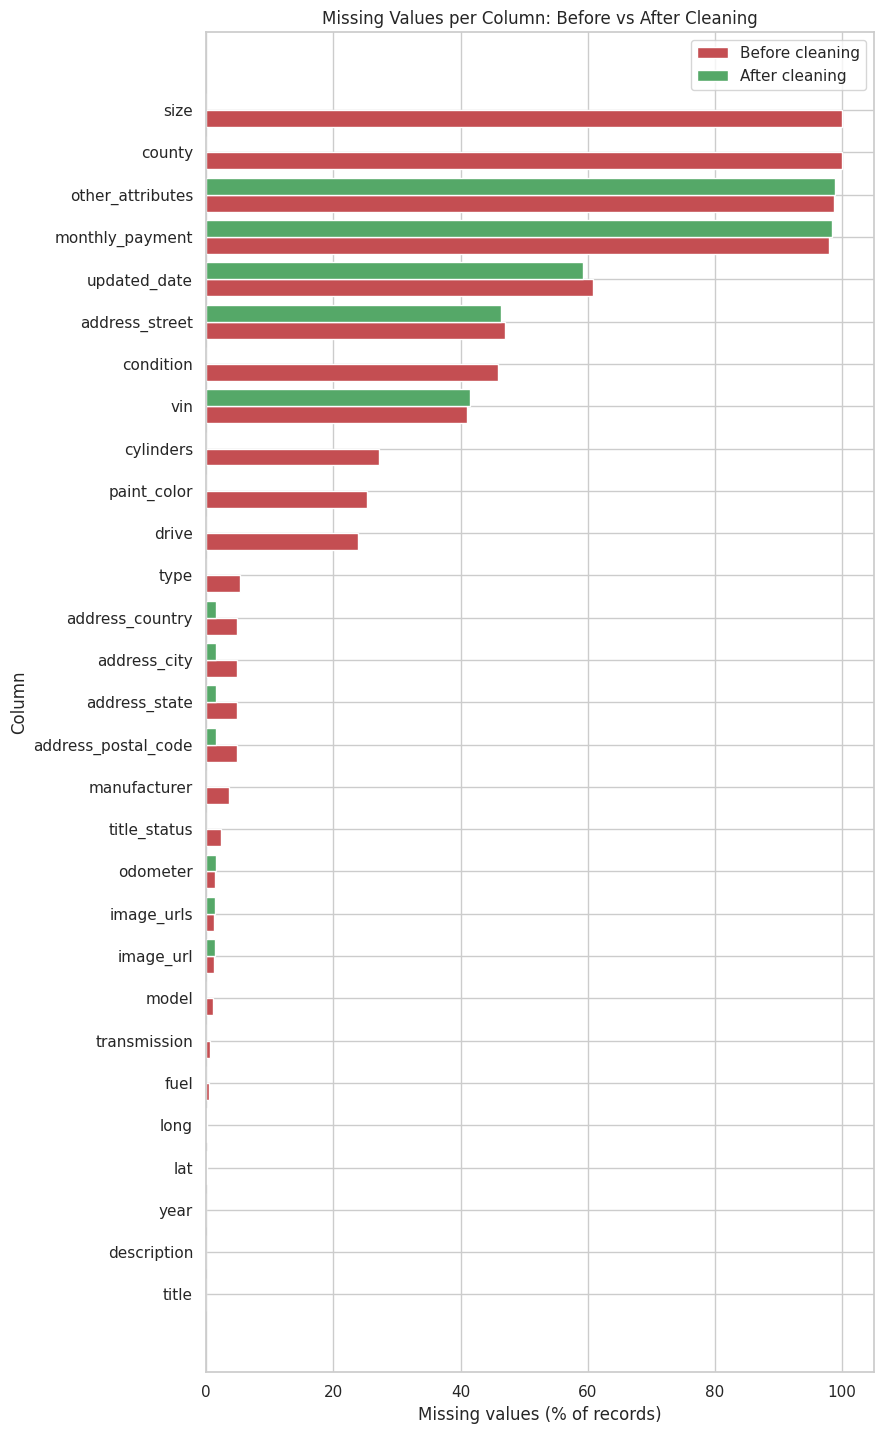

In [ ]:
# Combined missing-value report: before vs after (also exported in Section 16)
after_counts = df_cleaned.isna().sum()
missing_report_full = missing_report.copy()
missing_report_full["Missing After Cleaning"] = missing_report_full["Column"].map(lambda c: after_counts.get(std_name(c), np.nan))
missing_report_full["Status After Cleaning"] = np.where(missing_report_full["Missing After Cleaning"].isna(),
                                                        "Column removed (completely empty)", "Column retained")

compare = pd.DataFrame({
    "before": (df_working.isna().mean() * 100).rename(index=std_name),
    "after": (df_cleaned.isna().mean() * 100),
}).fillna(0)
compare = compare[(compare["before"] > 0) | (compare["after"] > 0)].sort_values("before")

fig, ax = plt.subplots(figsize=(9, max(3.5, 0.5 * len(compare))))
y_pos = np.arange(len(compare))
ax.barh(y_pos - 0.2, compare["before"], height=0.4, label="Before cleaning", color="#C44E52")
ax.barh(y_pos + 0.2, compare["after"], height=0.4, label="After cleaning", color="#55A868")
ax.set_yticks(y_pos)
ax.set_yticklabels(compare.index)
ax.set_title("Missing Values per Column: Before vs After Cleaning")
ax.set_xlabel("Missing values (% of records)")
ax.set_ylabel("Column")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretation – Section 14
- Compare each *Before* and *After* value: invalid-value and duplicate counts should drop to **0**, data-type issues should drop to **0**, and the total number of missing cells should fall.
- Some columns still contain missing values (year, odometer, coordinates, VIN, description…). This is a **documented limitation**: these gaps are real, and filling them with statistics from the whole dataset would risk data leakage. They are handled later inside the modelling pipeline.
- The data is **not claimed to be 100 % clean**: outliers are retained (and flagged) and seller-entered values cannot be verified for accuracy.

## 15. Final Dataset Validation

**What will happen?** A set of automatic checks verifies that `df_cleaned` satisfies the rules we cleaned for. If any check fails, the notebook stops with a clear message instead of silently continuing.

**Why?** Assertions turn our cleaning claims into tests, which supports reproducibility.

In [ ]:
validation = []
def check(name, condition, detail=""):
    validation.append({"Check": name, "Passed": bool(condition), "Detail": detail})

text_cat_cols = [c for c in CAT_COLS if c in df_cleaned.columns and is_text(df_cleaned[c])]

check("Dataset is not empty", len(df_cleaned) > 0, f"{len(df_cleaned):,} rows x {df_cleaned.shape[1]} columns")
check("Target column 'price' exists", "price" in df_cleaned.columns)
check("No missing target values", df_cleaned["price"].isna().sum() == 0)
check("All prices are positive and below the plausibility cap", ((df_cleaned["price"] > 0) & (df_cleaned["price"] < PRICE_MAX_PLAUSIBLE)).all())
check("No exact duplicate rows", df_cleaned.duplicated().sum() == 0)
if REMOVE_REPEATED_ADVERTS and len(REPEAT_KEY) >= 5:
    check("No re-posted adverts remain", df_cleaned.duplicated(subset=REPEAT_KEY).sum() == 0)
check("Column names are unique and standardised", df_cleaned.columns.is_unique and all(c == std_name(c) for c in df_cleaned.columns))
if "year" in df_cleaned.columns:
    yv = df_cleaned["year"].dropna()
    check("Year values are within the valid range", ((yv >= YEAR_MIN_VALID) & (yv <= MAX_VALID_YEAR)).all())
if "odometer" in df_cleaned.columns:
    ov = df_cleaned["odometer"].dropna()
    check("Odometer values are within the valid range", ((ov >= 0) & (ov <= ODOMETER_MAX_PLAUSIBLE)).all())
if {"lat", "long"} <= set(df_cleaned.columns):
    check("Coordinates are within the US range", ((df_cleaned["lat"].dropna().between(*US_LAT_RANGE)).all()
                                                  and (df_cleaned["long"].dropna().between(*US_LON_RANGE)).all()))
if "posting_date" in df_cleaned.columns:
    check("posting_date is a datetime column", pd.api.types.is_datetime64_any_dtype(df_cleaned["posting_date"]))
for std in EXPECTED_NUMERIC:
    if std in df_cleaned.columns:
        check(f"'{std}' is numeric", pd.api.types.is_numeric_dtype(df_cleaned[std]))
check("No blank strings / placeholders in categorical columns",
      all(df_cleaned[c].astype(str).str.strip().str.lower().isin(PLACEHOLDERS_EXCL_UNKNOWN).sum() == 0 for c in text_cat_cols))
check("No missing values in categorical columns that were filled", all(df_cleaned[c].isna().sum() == 0 for c in text_cat_cols if c in FILL_UNKNOWN_COLS))
check("Raw dataset unchanged (shape and columns)", df_raw.shape == RAW_SHAPE and list(df_raw.columns) == RAW_COLUMNS)
check("Working copy unchanged", df_raw.equals(df_working))
check("Row accounting: raw - removed = cleaned", len(df_raw) - records_removed == len(df_cleaned))

validation_table = pd.DataFrame(validation)
display(validation_table)

assert df_cleaned.shape[0] > 0
assert "price" in df_cleaned.columns
assert validation_table["Passed"].all(), "At least one validation check failed - see the table above."
print("All validation checks passed.")

,Check,Passed,Detail
0,Dataset is not empty,True,"240,186 rows x 43 columns"
1,Target column 'price' exists,True,
2,No missing target values,True,
3,All prices are positive and below the plausibility cap,True,
4,No exact duplicate rows,True,
5,No re-posted adverts remain,True,
6,Column names are unique and standardised,True,
7,Year values are within the valid range,True,
8,Odometer values are within the valid range,True,
9,Coordinates are within the US range,True,


All validation checks passed.


In [ ]:
def preview(df, n=5, tail=False):
    """Show the first/last rows with long text shortened for readability."""
    view = df.tail(n) if tail else df.head(n)
    return view.assign(**{c: view[c].astype(str).str.slice(0, 40) for c in ["description", "url", "image_url", "region_url"] if c in view.columns})

print(f"Final dataset shape: {df_cleaned.shape}")
print("\nColumn names:", list(df_cleaned.columns))
print("\nData types:")
display(df_cleaned.dtypes.astype(str).to_frame("dtype"))
print("\nFirst five records:")
display(preview(df_cleaned))
print("\nLast five records:")
display(preview(df_cleaned, tail=True))

Final dataset shape: (240186, 43)

Column names: ['id', 'url', 'region', 'region_url', 'price', 'year', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'odometer', 'title_status', 'transmission', 'vin', 'drive', 'type', 'paint_color', 'image_url', 'description', 'state', 'lat', 'long', 'posting_date', 'seller_type', 'title', 'updated_date', 'address_street', 'address_city', 'address_state', 'address_postal_code', 'address_country', 'image_count', 'image_urls', 'delivery_available', 'odometer_broken', 'odometer_rolled_over', 'monthly_payment', 'other_attributes', 'flag_price_iqr_outlier', 'flag_year_iqr_outlier', 'flag_odometer_iqr_outlier', 'flag_low_price']

Data types:


,dtype
id,int64
url,object
region,object
region_url,object
price,int64
year,Int64
manufacturer,object
model,object
condition,object
cylinders,object



First five records:


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,vin,drive,type,paint_color,image_url,description,state,lat,long,posting_date,seller_type,title,updated_date,address_street,address_city,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes,flag_price_iqr_outlier,flag_year_iqr_outlier,flag_odometer_iqr_outlier,flag_low_price
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunny,SF bay area,https://sfbay.craigslist.org,27999,2022,ford,explorer st,excellent,6 cylinders,gas,99179,clean,automatic,1FM5K8GCXNGA77516,4wd,suv,grey,https://images.craigslist.org/00N0N_aBzb,⭐ Autorace ⭐ 🏷️ STOCK #: 1726 📞 CALL OR,ca,37.371435,-122.047863,2026-11-03 03:24:16+00:00,dealer,2022 Ford Explorer ST,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4cO_0eI0b0_6...,0,0,0,NaN,NaN,False,False,False,False
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-,SF bay area,https://sfbay.craigslist.org,2200,1969,volkswagen,bug,fair,4 cylinders,gas,90000,clean,manual,NaN,rwd,other,green,https://images.craigslist.org/00n0n_gNzb,I am selling a 1969Vw Bug all original.,ca,37.906000,-122.545000,2026-11-03 03:23:52+00:00,owner,69 VW Bug All Original Runs and drives current registration,NaN,NaN,Mill Valley,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG4_0CI0t2_6...,0,0,0,NaN,NaN,False,True,False,False
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunny,SF bay area,https://sfbay.craigslist.org,15999,2016,rover,sport,excellent,6 cylinders,gas,82896,clean,automatic,SALWR2VF6GA636931,4wd,suv,white,https://images.craigslist.org/00Z0Z_3KNl,⭐ Autorace ⭐ 🏷️ STOCK #: 1544 📞 CALL OR,ca,37.371435,-122.047863,2026-11-03 03:22:44+00:00,dealer,2016 Land Rover Range Rover Sport 3.0L V6 Supercharged HSE,2026-11-02T19:22:45-0800,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2h_0eI0b0_6...,0,0,0,NaN,NaN,False,False,False,False
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-,SF bay area,https://sfbay.craigslist.org,12000,1974,cadillac,eldorado convertible,good,8 cylinders,gas,89687,clean,automatic,NaN,fwd,convertible,blue,https://images.craigslist.org/00s0s_4aCp,Reluctantly posting this beauty for sale,ca,38.321878,-122.306027,2026-11-03 03:22:42+00:00,owner,1974 Cadillac Eldorado Convertible,NaN,NaN,Napa,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUWf_0CI0t2_6...,0,0,0,NaN,NaN,False,True,False,False
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunny,SF bay area,https://sfbay.craigslist.org,18999,2009,dodge,challenger lc srt8,excellent,8 cylinders,gas,81724,clean,automatic,2B3LJ74W39H549395,rwd,coupe,orange,https://images.craigslist.org/00T0T_4wec,⭐ Autorace ⭐ 🏷️ STOCK #: 1621 📞 CALL OR,ca,37.371435,-122.047863,2026-11-03 03:21:10+00:00,dealer,2009 Dodge Challenger SRT8,NaN,975 West El Camino Real,Sunnyvale,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3h_0eI0b0_6...,0,0,0,NaN,NaN,False,False,False,False



Last five records:


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,vin,drive,type,paint_color,image_url,description,state,lat,long,posting_date,seller_type,title,updated_date,address_street,address_city,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes,flag_price_iqr_outlier,flag_year_iqr_outlier,flag_odometer_iqr_outlier,flag_low_price
295446,7978316265,https://zanesville.craigslist.org/ctd/d/,zanesville / cambridge,https://zanesville.craigslist.org,13977,2016,subaru,forester,excellent,4 cylinders,gas,84761,clean,automatic,NaN,4wd,suv,unknown,https://images.craigslist.org/00P0P_g2md,--2016 Subaru Forester-- Only 84k miles!,oh,40.027474,-81.570694,2026-10-05 15:59:16+00:00,dealer,2016 Subaru Forester 2.5i Limited AWD,NaN,2001 E WHEELING AVE,Cambridge,OH,43725,US,17,https://images.craigslist.org/00P0P_g2md0GCU3AJ_0cU08C_6...,0,0,0,NaN,NaN,False,False,False,False
295447,7978068858,https://zanesville.craigslist.org/cto/d/,zanesville / cambridge,https://zanesville.craigslist.org,5500,2004,chevrolet,2500 6.6 diesel,fair,8 cylinders,diesel,351350,clean,automatic,NaN,4wd,pickup,red,https://images.craigslist.org/00505_1czg,I have a 2004 Chevy 2500 duramax 4x4 cre,oh,39.818700,-82.079200,2026-10-05 00:21:43+00:00,owner,2004 Chevy 2500 duramax,NaN,NaN,Roseville,OH,43777,US,13,https://images.craigslist.org/00505_1czgViYDqYb_0t20CI_6...,0,0,0,NaN,NaN,False,False,True,False
295448,7977713163,https://zanesville.craigslist.org/ctd/d/,zanesville / cambridge,https://zanesville.craigslist.org,66800,2027,unknown,mini-t camper van | garageable rv,new,6 cylinders,gas,16,clean,automatic,2C4RC3BG9VR574345,4wd,van,unknown,https://images.craigslist.org/00X0X_9QkT,2027 Chrysler Pacifica AWD Mini-T Camper,oh,44.120200,-94.218400,2026-10-04 11:06:23+00:00,dealer,2027 Mini-T Campervan Garageable RV for Road Trips Near ...,2026-10-06T14:55:52-0400,NaN,Lake Crystal,MN,56055,US,24,https://images.craigslist.org/00X0X_9QkTWtjlxHq_0CI0pO_6...,1,0,0,NaN,NaN,True,False,False,False
295449,7977443604,https://zanesville.craigslist.org/cto/d/,zanesville / cambridge,https://zanesville.craigslist.org,5850,2017,chevrolet,traverse lt,good,6 cylinders,gas,157000,clean,automatic,NaN,fwd,suv,white,https://images.craigslist.org/00K0K_fuiv,"3 row seating, front wheel drive Travers",oh,39.899728,-81.347923,2026-10-03 19:05:37+00:00,owner,2017 Chevy Traverse LT,NaN,25900 LASHLEY RD,Senecaville,OH,43780,US,8,https://images.craigslist.org/00K0K_fuivMPDJfU3_0t50CI_6...,0,0,0,NaN,NaN,False,False,False,False
295450,7976716941,https://zanesville.craigslist.org/ctd/d/,zanesville / cambridge,https://zanesville.craigslist.org,9977,2016,kia,rio,like new,4 cylinders,gas,35736,clean,automatic,NaN,fwd,sedan,unknown,https://images.craigslist.org/00l0l_fuxA,--2016 Kia Rio LX-- Only 35k original mi,oh,40.027474,-81.570694,2026-10-02 15:59:09+00:00,dealer,2016 Kia Rio LX - ONLY 35K MILES!,NaN,2001 E WHEELING AVE,Cambridge,OH,43725,US,15,https://images.craigslist.org/00l0l_fuxA70bzlgK_0cU08C_6...,0,0,0,NaN,NaN,False,False,False,False


### Interpretation – Section 15
If every check shows `True`, `df_cleaned` is **suitable as the input of Stage 4** (exploratory analysis and feature engineering).

This does **not** mean the data is ready for modelling as it is: remaining missing values still need imputation *inside the training pipeline*, categorical variables must be encoded, and features will be engineered in the following stages.

## 16. Export Cleaned Dataset and Supporting Files

**What will happen?** A project folder with the required structure is created, and the cleaned dataset, reports, a small sample and documentation are saved.

```text
Used-Vehicle-Price-Prediction/
├── data/        raw/  processed/vehicles_cleaned.csv  sample/
├── outputs/     reports (CSV) and figures/
├── notebooks/   put the four notebooks here (01_..., 02_..., 03_..., 04_...)
├── models/      trained model (Stage 7)
├── app/         Streamlit app (Stage 7)
├── src/         shared Python code (Stage 7)
└── docs/        data dictionary
```

**Important:**
- The raw dataset is never overwritten.
- Everything is saved in **Google Drive** (`MyDrive/Used-Vehicle-Price-Prediction`) because notebooks 02, 03 and 04 read these files. Colab's temporary storage is deleted when the session ends.
- GitHub rejects files above **100 MB**: the full cleaned CSV is usually too large, so only the sample goes to GitHub.

In [ ]:
# ----------------------------- SETTINGS -----------------------------
COPY_RAW_FILE = False                      # True = also copy the raw CSV into data/raw/ (large file)
DOWNLOAD_STAGE3_REPORTS = True             # True = download a small zip with the reports and sample
# --------------------------------------------------------------------

if IN_COLAB:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Used-Vehicle-Price-Prediction")     # shared by notebooks 01-04
else:
    PROJECT_DIR = Path("Used-Vehicle-Price-Prediction")

RAW_DIR, PROCESSED_DIR, SAMPLE_DIR = PROJECT_DIR / "data/raw", PROJECT_DIR / "data/processed", PROJECT_DIR / "data/sample"
OUTPUT_DIR, FIG_DIR = PROJECT_DIR / "outputs", PROJECT_DIR / "outputs/figures"
NOTEBOOK_DIR, MODEL_DIR, APP_DIR, SRC_DIR, DOCS_DIR = (PROJECT_DIR / n for n in ["notebooks", "models", "app", "src", "docs"])
for folder in [RAW_DIR, PROCESSED_DIR, SAMPLE_DIR, OUTPUT_DIR, FIG_DIR, NOTEBOOK_DIR, MODEL_DIR, APP_DIR, SRC_DIR, DOCS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
print(f"Project folder: {PROJECT_DIR}")

# Optional: copy (never move or overwrite) the raw file
if COPY_RAW_FILE:
    target = RAW_DIR / DATA_PATH.name
    if target.exists():
        print("Raw file already in data/raw - not overwritten.")
    elif DATA_PATH.resolve() != target.resolve():
        shutil.copy2(DATA_PATH, target)
        print("Raw file copied to data/raw.")

# Cleaned dataset
cleaned_path = PROCESSED_DIR / "vehicles_cleaned.csv"
df_cleaned.to_csv(cleaned_path, index=False)
cleaned_size_mb = cleaned_path.stat().st_size / 1024**2
print(f"Saved cleaned dataset: {cleaned_path.name} ({cleaned_size_mb:,.1f} MB, {len(df_cleaned):,} rows)")

# Small representative sample (suitable for GitHub)
sample_path = SAMPLE_DIR / "vehicles_cleaned_sample.csv"
PRIVATE_COLUMNS = ["description", "vin", "url", "region_url", "image_url", "image_urls", "title", "address_street", "address_city",
                   "address_state", "address_postal_code", "address_country", "other_attributes"]
public_sample = df_cleaned.sample(n=min(5000, len(df_cleaned)), random_state=42).drop(columns=[c for c in PRIVATE_COLUMNS if c in df_cleaned.columns])
public_sample.to_csv(sample_path, index=False)          # identifying / free-text columns are NOT included in the public sample
print(f"Saved sample: {sample_path.name} ({sample_path.stat().st_size / 1024**2:,.2f} MB)")

# Reports
reports = {
    "missing_value_report.csv": missing_report_full,
    "duplicate_report.csv": duplicate_report,
    "cleaning_audit_log.csv": audit_log_df,
    "data_dictionary.csv": data_dictionary,
    "before_after_quality_report.csv": before_after,
    "excluded_price_records_log.csv": excluded_records,
    "cleaning_summary.csv": cleaning_summary,
}
for filename, table in reports.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
data_dictionary.to_csv(DOCS_DIR / "data_dictionary.csv", index=False)

# Settings that notebooks 02-04 need (so that they use exactly the same rules)
cleaning_settings = {"DATA_COLLECTION_YEAR": int(DATA_COLLECTION_YEAR), "PRICE_MAX_PLAUSIBLE": PRICE_MAX_PLAUSIBLE,
                     "PRICE_LOW_REVIEW": PRICE_LOW_REVIEW, "YEAR_MIN_VALID": YEAR_MIN_VALID,
                     "ODOMETER_MAX_PLAUSIBLE": ODOMETER_MAX_PLAUSIBLE, "records_raw": int(len(df_raw)),
                     "records_cleaned": int(len(df_cleaned)), "duplicates_removed": int(removed_duplicates),
                     "price_records_excluded": int(n_price_excluded), "repeated_adverts_removed": int(removed_repeated)}
(OUTPUT_DIR / "cleaning_settings.json").write_text(json.dumps(cleaning_settings, indent=2), encoding="utf-8")
print("Saved reports:", ", ".join(reports))

if cleaned_size_mb > 100:
    print(f"\nWARNING: the cleaned CSV is {cleaned_size_mb:,.0f} MB - above GitHub's 100 MB limit. Do NOT upload it; "
          "upload only the sample and describe how to regenerate the file (see data/README_DATA.md).")

# Documentation for the repository
(PROJECT_DIR / "data/README_DATA.md").write_text(f"""# Data instructions

* **Source:** Craigslist Cars and Trucks Dataset (Austin Reese), https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data
* **Licence:** see the licence shown on the Kaggle dataset page.
* **Raw file:** `vehicles.csv` (download manually from Kaggle; it is NOT stored in this repository because of its size).
* **Cleaned file:** `data/processed/vehicles_cleaned.csv` ({len(df_cleaned):,} rows). Regenerate it by running the notebook
  from the first cell with the raw file. It is too large for GitHub (limit 100 MB), so a 5,000-row random sample is provided in `data/sample/`.
* **Cleaning decisions:** see `outputs/cleaning_audit_log.csv` and `outputs/before_after_quality_report.csv`.
""", encoding="utf-8")

print("\nProject files created:")
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(f"  {path.relative_to(PROJECT_DIR)}  ({path.stat().st_size / 1024:,.0f} KB)")

Project folder: /content/drive/MyDrive/Used-Vehicle-Price-Prediction
Saved cleaned dataset: vehicles_cleaned.csv (899.3 MB, 240,186 rows)
Saved sample: vehicles_cleaned_sample.csv (1.03 MB)
Saved reports: missing_value_report.csv, duplicate_report.csv, cleaning_audit_log.csv, data_dictionary.csv, before_after_quality_report.csv, excluded_price_records_log.csv, cleaning_summary.csv


Project files created:
  data/README_DATA.md  (1 KB)
  data/processed/vehicles_cleaned.csv  (920,910 KB)
  data/sample/vehicles_cleaned_sample.csv  (1,050 KB)
  docs/data_dictionary.csv  (6 KB)
  outputs/before_after_quality_report.csv  (2 KB)
  outputs/cleaning_audit_log.csv  (10 KB)
  outputs/cleaning_settings.json  (0 KB)
  outputs/cleaning_summary.csv  (0 KB)
  outputs/data_dictionary.csv  (6 KB)
  outputs/duplicate_report.csv  (1 KB)
  outputs/excluded_price_records_log.csv  (453 KB)
  outputs/missing_value_report.csv  (3 KB)


In [ ]:
# Download a small zip (reports + sample + data README). The full CSV stays in the project folder.
if DOWNLOAD_STAGE3_REPORTS:
    stage = Path("stage3_package")
    shutil.rmtree(stage, ignore_errors=True)
    shutil.copytree(OUTPUT_DIR, stage / "outputs", ignore=shutil.ignore_patterns("figures"))
    shutil.copytree(SAMPLE_DIR, stage / "data/sample")
    shutil.copy2(PROJECT_DIR / "data/README_DATA.md", stage / "README_DATA.md")
    zip_path = shutil.make_archive("stage3_reports_and_sample", "zip", stage)
    print(f"Created {zip_path}")
    if IN_COLAB:
        from google.colab import files
        files.download(zip_path)

Created /content/stage3_reports_and_sample.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 17. Conclusion of Stage 3

This stage inspected the Craigslist vehicle-listing data systematically and measured its quality along six dimensions: completeness, uniqueness, consistency, validity, accuracy and data-type correctness. The assessment found missing values (including a completely empty column and heavy gaps in several descriptive attributes), exact duplicate records, hidden blank/placeholder values, columns stored in the wrong type, impossible or implausible prices, years, mileage and coordinates, and statistical outliers.

The cleaning workflow answered each problem with a justified, documented decision. Exact duplicates were removed because they carry no extra information. Records without a valid asking price were excluded because the target must never be imputed, while remaining records with impossible *feature* values were kept and the invalid value was set to missing. Categorical gaps were given an explicit `unknown` category, and no statistic was learned from the data, which avoids data leakage. Statistical outliers were flagged rather than deleted because luxury, classic and high-mileage vehicles are genuine market segments. Every action is in the audit log with its real count.

The before-and-after comparison shows that duplicates, invalid values and data-type problems were resolved and that the total number of missing cells fell. Limitations remain: year, odometer, coordinates, VIN and description still contain genuine missing values, asking prices cannot be verified for accuracy, and the thresholds for implausible values are documented assumptions. The cleaned dataset is suitable as the input of Stage 4, where exploratory analysis and feature engineering will follow and remaining gaps will be handled inside a leakage-free modelling pipeline.

In [ ]:
# Key results of THIS run (generated from the actual data)
print("KEY RESULTS OF STAGE 3")
print("-" * 60)
print(f"Raw records                      : {len(df_raw):,}")
print(f"Cleaned records                  : {len(df_cleaned):,} ({len(df_cleaned) / len(df_raw) * 100:.1f}% retained)")
print(f"  exact duplicates removed       : {removed_duplicates:,}")
print(f"  invalid/implausible prices     : {n_price_excluded:,}")
print(f"Missing cells before -> after    : {quality_before['Missing values (NaN cells)']:,} -> {quality_after['Missing values (NaN cells)']:,}")
print(f"Values standardised              : {counters['values_standardised']:,}")
print(f"Invalid values set to missing    : {counters['invalid_values_set_to_missing']:,}")
print(f"Columns with remaining missing   : {int((df_cleaned.isna().sum() > 0).sum())}")
print("-" * 60)
print("Stage 3 complete. df_cleaned is the input of Stage 4.")

KEY RESULTS OF STAGE 3
------------------------------------------------------------
Raw records                      : 295,451
Cleaned records                  : 240,186 (81.3% retained)
  exact duplicates removed       : 0
  invalid/implausible prices     : 10,361
Missing cells before -> after    : 2,081,120 -> 852,541
Values standardised              : 97,439
Invalid values set to missing    : 263
Columns with remaining missing   : 17
------------------------------------------------------------
Stage 3 complete. df_cleaned is the input of Stage 4.


---
## Next step
Notebook 01 is finished. The cleaned dataset and all Stage 3 reports are saved in your Drive folder `Used-Vehicle-Price-Prediction`.

**Open notebook `02_stage_4_eda_feature_engineering.ipynb` next.**